# Avance 5. Modelo final: ensambles homogéneos de ResNet50

## Predicción de propiedades físicas de galaxias a partir de imágenes GRZ y redshift

Instituto Tecnológico y de Estudios Superiores de Monterrey (ITESM) · Equipo 24

José Florencio Maguey Peralta — A01796727  
Erick Alberto Bustos Cruz — A01378966  
Luz Copelia Minutti Pérez — A01796921

Asesores científicos: Dr. Héctor Hernández Toledo y Dr. José Antonio Vázquez Mata.  
Asesor ITESM: Dr. Iván Reyes Amezcua.


## Presentación

En este notebook desarrollamos dos ensambles homogéneos a partir de las redes ResNet50 que entrenamos en la etapa anterior. Buscamos evaluar si la combinación de sus predicciones mejora la estimación de la masa estelar, la tasa de formación estelar y el índice D4000.

Trabajamos con los siguientes modelos:

| Nombre del ensamble | Redes que lo integran | Configuración de las redes base |
|---|---|---|
| Ensamble ResNet50 D | Variante D con semillas 42, 7 y 2026 | Imágenes GRZ, redshift y pérdida MSE |
| Ensamble ResNet50 E | Variante E con semillas 42, 7 y 2026 | Imágenes GRZ, redshift y pérdida Huber |

Para cada ensamble evaluamos el promedio uniforme y distintas combinaciones ponderadas. Ajustamos los parámetros de combinación y comparamos su desempeño con ResNet50_E_s42, nuestro mejor modelo individual de la fase previa.

Ordenamos los resultados por MSE normalizado global e incorporamos MAE, RMSE, sesgo, R² y los tiempos disponibles de entrenamiento. Finalmente, analizamos las predicciones y los residuos del candidato elegido mediante cuatro gráficos con sus interpretaciones.

Con esta entrega aportamos los dos ensambles homogéneos que integraremos con las estrategias heterogéneas del equipo para seleccionar el modelo final del proyecto.

# Ensambles homogéneos de ResNet50 para predecir propiedades de galaxias

En esta etapa combinamos las redes ResNet50 que entrenamos en el experimento A–G para predecir masa estelar, tasa de formación estelar y D4000. Construimos dos ensambles homogéneos: uno con las tres semillas de la variante D y otro con las tres semillas de la variante E. Conservamos sus imágenes GRZ, su incorporación de redshift y sus transformaciones originales. La diferencia entre las familias es la pérdida utilizada al entrenar las redes: MSE en D y Huber en E.

Partimos de las predicciones guardadas por las seis redes. Evaluamos el promedio uniforme y combinaciones ponderadas, ajustamos los hiperparámetros del combinador y comparamos el resultado con ResNet50_E_s42. Mantenemos como criterio principal el MSE normalizado global y lo acompañamos con MAE, RMSE, sesgo y R² por propiedad, además de los tiempos de entrenamiento.

Desarrollamos aquí la parte homogénea del trabajo. Con estos dos ensambles y los dos heterogéneos del equipo completaremos los cuatro solicitados en la rúbrica. Nuestros dos ensambles pertenecen a la misma familia de agregación y utilizan redes base diferentes; no los presentamos como cuatro algoritmos distintos.

Al ejecutar el notebook de principio a fin, generamos las búsquedas, las tablas, cuatro gráficos interpretados del candidato elegido y una conclusión que identifica el mejor resultado observado. No anticipamos un ganador ni presentamos como ejecutadas pruebas que todavía no hemos realizado.

## 1. Configuración y parámetros que vamos a evaluar

Utilizamos la carpeta de resultados del experimento A–G en el servidor. Si trasladamos esos resultados a otro equipo, cambiamos `carpeta_ag` por la carpeta que contiene `muestra_lista.csv`, `estadisticos_Train.json` y `corridas/`. Necesitamos los seis archivos `predicciones_Validation.csv` de D y E y, para recuperar los tiempos, sus archivos `multitarea/historial.csv`. Trabajamos con NumPy, pandas y Matplotlib; la comparación de predicciones no requiere cargar las imágenes, los pesos de las redes ni una GPU. La sección 12 añade inferencia con las imágenes y los checkpoints para estudiar su importancia.

Elegimos los siguientes valores antes de observar los resultados de los nuevos ensambles:

| Parámetro | Valores o configuración | Motivo |
|---|---|---|
| Redes por ensamble | Tres; semillas 42, 7 y 2026 | Aprovechamos todas las corridas disponibles de cada variante y mantenemos fijo el conjunto de integrantes. |
| Promedio uniforme | Un peso de 1/3 para cada red | Lo usamos como referencia sencilla, sin parámetros aprendidos. |
| Regularización λ | 0, 0.001, 0.01, 0.1, 1 y 10 | Cubrimos desde un ajuste sin penalización hasta una preferencia fuerte por repartir los pesos de forma uniforme. Incluimos valores menores y mayores que 0.1, sin asumir cuál será mejor. |
| Alcance de los pesos | Global y por objetivo | Contrastamos una combinación compartida por las tres propiedades con combinaciones que permiten aprovechar diferencias entre masa, SFR y D4000. |
| Restricciones | Pesos no negativos; suma igual a uno | Conservamos la escala de cada propiedad y evitamos extrapolar fuera de las predicciones de las redes por medio de pesos negativos. |
| Validación del combinador | Cinco pliegues externos y cuatro internos | Separamos la elección de parámetros de la evaluación de cada pliegue, manteniendo un número suficiente de galaxias en cada ajuste. |
| Semilla de particiones | 2026 | Fijamos divisiones reproducibles e idénticas para ambos ensambles. No buscamos una semilla que produzca mejores métricas. |
| Bootstrap diagnóstico | 1,000 repeticiones; semilla 321 | Resumimos cómo varía la diferencia de error al remuestrear las mismas galaxias. |

Con las opciones iniciales evaluamos trece configuraciones por ensamble: el promedio uniforme y doce combinaciones de alcance y regularización. La búsqueda elegirá los parámetros con los datos; las tablas posteriores mostrarán cuáles se probaron y por qué se seleccionó la configuración final.

In [1]:
import json, hashlib, itertools, time, os, platform, zipfile
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import display, Markdown, FileLink

VERSION = 'ENSAMBLES_RESNET_DE_1.0.0'
OBJETIVOS = ['log_mstar', 'log_sfr', 'd4000']
SEMILLAS = [42, 7, 2026]
VARIANTES = {'D': 'D_multi_grz_z_mse', 'E': 'E_multi_grz_z_huber'}
BASE_INDIVIDUAL = 'ResNet50_E_s42'
CFG = {
    'carpeta_ag': str(Path.home() / 'DESI_experimentos_mejorados' /
                      'desi_comparacion_A_G_v01' / '0dc2ac47a31c'),
    'carpeta_salida': str(Path.home() / 'DESI_ensambles_homogeneos'),
    'n_train_esperado': 7121, 'n_validation_esperado': 1261,
    'pliegues_externos': 5, 'pliegues_internos': 4, 'semilla_cv': 2026,
    'lambdas': [0.0, 0.001, 0.01, 0.1, 1.0, 10.0],
    'alcances': ['global', 'por_objetivo'],
    'bootstrap_repeticiones': 1000, 'semilla_bootstrap': 321,
    'evaluar_test': False,
    # Opcional: métricas de otros candidatos con el formato de referencia explicado abajo.
    'csv_referencias_equipo': '',
}
pd.set_option('display.max_columns', 30, 'display.precision', 6)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})


## 2. Recuperación de las seis corridas

Verificamos que todas las corridas contienen exactamente las mismas galaxias de Validation, con las mismas etiquetas y redshift. Las alineamos mediante `mangaid`, independientemente del orden de sus CSV. También comprobamos que las escalas de normalización corresponden a las 7,121 galaxias de Train.

Recuperamos los tiempos sumando la duración de todas las épocas registradas para cada red. Ese valor representa el costo de su entrenamiento original, no una nueva ejecución. Si un historial no está disponible, dejamos el tiempo sin dato en lugar de estimarlo. Conservamos los archivos A–G y escribimos los nuevos resultados en una carpeta aparte.

In [2]:
def hash_archivo(ruta):
    h = hashlib.sha256()
    with Path(ruta).open('rb') as f:
        for bloque in iter(lambda: f.read(1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()

def json_nativo(x):
    if isinstance(x, np.ndarray): return x.tolist()
    if isinstance(x, np.generic): return x.item()
    if isinstance(x, Path): return str(x)
    raise TypeError(type(x).__name__)

def serializar(x):
    return json.dumps(x, ensure_ascii=False, sort_keys=True, allow_nan=False,
                      default=json_nativo, indent=2)

def guardar_json(x, ruta):
    ruta = Path(ruta)
    temporal = ruta.with_name(ruta.name + '.tmp')
    temporal.write_text(serializar(x), encoding='utf-8')
    os.replace(temporal, ruta)

def guardar_csv(tabla, ruta):
    ruta = Path(ruta)
    temporal = ruta.with_name(ruta.name + '.tmp')
    tabla.to_csv(temporal, index=False)
    os.replace(temporal, ruta)

def cargar_fuentes(cfg):
    if cfg['evaluar_test'] is not False:
        raise ValueError('Este notebook termina en Validation; no implementa evaluación de Test.')
    raiz = Path(cfg['carpeta_ag']).expanduser().resolve()
    requeridos = ['muestra_lista.csv', 'estadisticos_Train.json']
    for nombre in requeridos:
        if not (raiz / nombre).is_file():
            raise FileNotFoundError(f'Falta {nombre} en {raiz}. Revisa carpeta_ag en la configuración.')
    fuentes = []
    def registrar(p):
        fuentes.append({'archivo': str(p.relative_to(raiz)), 'sha256': hash_archivo(p)})
    def csv(p, **kw):
        registrar(p)
        return pd.read_csv(p, **kw)
    muestra = csv(raiz / 'muestra_lista.csv', dtype={'mangaid': 'string'})
    necesarias = {'mangaid', 'particion', 'redshift', *OBJETIVOS}
    if not necesarias.issubset(muestra): raise ValueError('La muestra no contiene las columnas necesarias.')
    if (muestra.mangaid.isna().any() or muestra.mangaid.duplicated().any()
        or not muestra.particion.isin(['Train', 'Validation', 'Test']).all()):
        raise ValueError('Identificadores o particiones incorrectos en la muestra.')
    # El catálogo conserva las particiones originales; solo usamos filas de desarrollo.
    train = muestra.loc[muestra.particion.eq('Train')].copy().sort_values('mangaid')
    val = muestra.loc[muestra.particion.eq('Validation')].copy().sort_values('mangaid').reset_index(drop=True)
    for nombre, tabla, esperado in [('Train', train, cfg['n_train_esperado']),
                                     ('Validation', val, cfg['n_validation_esperado'])]:
        if len(tabla) != esperado: raise ValueError(f'{nombre}: esperábamos {esperado} galaxias y encontramos {len(tabla)}.')
        if not np.isfinite(tabla[[*OBJETIVOS, 'redshift']].to_numpy(float)).all():
            raise ValueError(f'Datos no finitos en {nombre}.')
    pstats = raiz / 'estadisticos_Train.json'
    registrar(pstats)
    stats = json.loads(pstats.read_text())
    escala = np.asarray(stats['y_std'], float)
    media = np.asarray(stats['y_media'], float)
    if (escala.shape != (3,) or not np.isfinite(escala).all() or np.any(escala <= 0)
        or media.shape != (3,) or not np.isfinite(media).all()):
        raise ValueError('Estadísticos de etiquetas no válidos.')
    if (stats['n_train'] != len(train) or sorted(stats['ids_train']) != train.mangaid.tolist()
        or not np.allclose(escala, train[OBJETIVOS].std(ddof=0), rtol=1e-8, atol=1e-10)
        or not np.allclose(media, train[OBJETIVOS].mean(), rtol=1e-8, atol=1e-10)):
        raise ValueError('Los estadísticos no corresponden al Train de esta muestra.')
    datos, corridas = {}, []
    for letra, variante in VARIANTES.items():
        predicciones = []
        for semilla in SEMILLAS:
            carpetas = sorted(p for p in (raiz / 'corridas').glob(f'{variante}_s{semilla}_*')
                              if (p / 'predicciones_Validation.csv').is_file())
            if len(carpetas) != 1:
                raise RuntimeError(f'{variante}, semilla {semilla}: encontramos {len(carpetas)} corridas. '
                                   'Necesitamos una sola corrida completa por variante y semilla.')
            carpeta = carpetas[0]
            p = carpeta / 'predicciones_Validation.csv'
            t = csv(p, dtype={'mangaid': 'string'})
            columnas = ['pred_' + y for y in OBJETIVOS]
            if not {'mangaid', 'particion', 'variante', 'semilla', 'redshift', *OBJETIVOS, *columnas}.issubset(t):
                raise ValueError(f'Faltan columnas en {p}.')
            if (t.mangaid.isna().any() or t.mangaid.duplicated().any()
                or not t.particion.eq('Validation').all() or not t.variante.eq(variante).all()
                or not t.semilla.eq(semilla).all()):
                raise ValueError(f'Identidad de corrida incorrecta: {p}.')
            t = t.sort_values('mangaid').reset_index(drop=True)
            if t.mangaid.tolist() != val.mangaid.tolist():
                raise ValueError('Las corridas no contienen exactamente las mismas galaxias de Validation.')
            if not np.allclose(t[[*OBJETIVOS, 'redshift']], val[[*OBJETIVOS, 'redshift']], rtol=0, atol=1e-6):
                raise ValueError(f'Etiquetas o redshift distintos en {p}.')
            pred = t[columnas].to_numpy(float)
            if not np.isfinite(pred).all(): raise ValueError(f'Predicciones no finitas en {p}.')
            predicciones.append(pred)
            # Historial de todas las épocas ejecutadas, no solo hasta el mejor checkpoint.
            hist = carpeta / 'multitarea' / 'historial.csv'
            minutos = None
            if hist.is_file():
                h = csv(hist)
                if {'epoca', 'segundos'}.issubset(h):
                    if (h.empty or h.epoca.duplicated().any() or not np.isfinite(h.segundos).all()
                        or (h.segundos < 0).any()): raise ValueError(f'Historial temporal inválido: {hist}')
                    minutos = float(h.segundos.sum() / 60)
            experimento = carpeta / 'experimento.json'
            if experimento.is_file():
                registrar(experimento)
                doc = json.loads(experimento.read_text())
                if doc.get('variante') != variante or doc.get('semilla') != semilla:
                    raise ValueError(f'Configuración de otra corrida: {experimento}')
            corridas.append({'modelo': f'ResNet50_{letra}_s{semilla}', 'variante': letra,
                             'semilla': semilla, 'carpeta': str(carpeta),
                             'predicciones_sha256': hash_archivo(p),
                             'checkpoint': str(carpeta / 'multitarea' / 'mejor.pt'),
                             'minutos_entrenamiento': minutos})
        datos[letra] = np.stack(predicciones, axis=1)  # galaxia, red, propiedad
    return val, escala, datos, pd.DataFrame(corridas), fuentes


In [3]:
VALIDACION, ESCALA_TRAIN, PREDICCIONES, CORRIDAS, FUENTES = cargar_fuentes(CFG)
Y = VALIDACION[OBJETIVOS].to_numpy(float)
PROTOCOLO = {'version': VERSION, 'objetivos': OBJETIVOS, 'semillas_redes': SEMILLAS,
             'configuracion': {k: v for k, v in CFG.items() if k not in ['carpeta_ag', 'carpeta_salida', 'csv_referencias_equipo']},
             'fuentes': FUENTES, 'numpy': np.__version__, 'pandas': pd.__version__}
IDENTIDAD = hashlib.sha256(serializar(PROTOCOLO).encode()).hexdigest()[:16]
SALIDA = Path(CFG['carpeta_salida']).expanduser().resolve() / IDENTIDAD
if SALIDA == Path(CFG['carpeta_ag']).expanduser().resolve() or Path(CFG['carpeta_ag']).expanduser().resolve() in SALIDA.parents:
    raise ValueError('La salida debe estar fuera de la carpeta original A–G.')
SALIDA.mkdir(parents=True, exist_ok=True)
guardar_json(PROTOCOLO, SALIDA / 'protocolo.json')
guardar_csv(CORRIDAS, SALIDA / 'corridas_base.csv')
print(f'Reunimos {len(VALIDACION):,} galaxias y seis redes ya entrenadas.')
display(CORRIDAS[['modelo', 'minutos_entrenamiento']])
print('Resultados:', SALIDA)


Reunimos 1,261 galaxias y seis redes ya entrenadas.


,modelo,minutos_entrenamiento
0,ResNet50_D_s42,40.582615
1,ResNet50_D_s7,30.974005
2,ResNet50_D_s2026,38.282617
3,ResNet50_E_s42,39.630636
4,ResNet50_E_s7,34.704154
5,ResNet50_E_s2026,32.707908


Resultados: /home/a01796921/DESI_ensambles_homogeneos/2ea9b720bdfab52f


## 3. Criterio de comparación

Calculamos el error de cada propiedad en su escala original. Expresamos los errores de `log_mstar` y `log_sfr` en dex, mientras que D4000 es adimensional. Definimos el sesgo como predicción menos referencia; un valor positivo representa sobreestimación media.

Para comparar propiedades con dispersiones diferentes, dividimos cada MSE por la varianza de sus etiquetas de Train. Promediamos después los tres errores normalizados:

\[
\mathrm{MSE}_{\mathrm{global}}=
\frac{1}{3}\sum_{j=1}^{3}\frac{\frac{1}{N}\sum_{i=1}^{N}(\hat y_{ij}-y_{ij})^2}
{\sigma_{j,\mathrm{Train}}^2}.
\]

Así mantenemos el criterio utilizado en la fase individual. Calculamos el MSE global a partir de las predicciones de todas las galaxias; no promediamos sin ponderación las métricas de pliegues de distinto tamaño.

In [4]:
def criterio(y, pred, escala):
    return float(np.mean(((np.asarray(pred) - np.asarray(y)) / escala) ** 2))

def metricas_modelo(nombre, y, pred, escala, tipo='Ensamble homogéneo'):
    filas = []
    for j, objetivo in enumerate(OBJETIVOS):
        error = pred[:, j] - y[:, j]
        mse = float(np.mean(error ** 2))
        var = float(np.mean((y[:, j] - y[:, j].mean()) ** 2))
        filas.append({'modelo': nombre, 'tipo': tipo, 'objetivo': objetivo,
                      'unidad': 'adimensional' if objetivo == 'd4000' else 'dex', 'n': len(y),
                      'MAE': float(np.mean(np.abs(error))), 'RMSE': float(np.sqrt(mse)),
                      'sesgo': float(np.mean(error)), 'R2': 1 - mse / var if var > 0 else np.nan,
                      'MSE_normalizado': mse / escala[j] ** 2})
    return pd.DataFrame(filas)

def pliegues(n, k, semilla):
    if not isinstance(k, int) or not 2 <= k <= n // 2:
        raise ValueError('Necesitamos al menos dos galaxias por pliegue.')
    orden = np.random.default_rng(semilla).permutation(n)
    grupos = np.array_split(orden, k)
    return [(np.sort(np.concatenate([g for j, g in enumerate(grupos) if j != i])), np.sort(g))
            for i, g in enumerate(grupos)]


## 4. Construcción de los ensambles D y E

Para cada galaxia combinamos las predicciones de las tres semillas. Una vez obtenida la predicción conjunta, calculamos sus métricas. Esto es distinto de promediar las métricas individuales de las semillas.

En las combinaciones ponderadas minimizamos el error normalizado e incorporamos una penalización que acerca los pesos al promedio uniforme:

\[
\min_{w\geq0,\,\sum_m w_m=1}
\mathrm{MSE}_{\mathrm{normalizado}}(w)
+\lambda\sum_{m=1}^{3}(w_m-1/3)^2.
\]

Con λ = 0 dejamos que el error determine los pesos. Al aumentar λ favorecemos combinaciones más equilibradas. Cuando usamos alcance global, aprendemos los mismos tres pesos para todas las propiedades. Con alcance por objetivo resolvemos una combinación para cada propiedad. Comparamos ambas alternativas con el mismo criterio global.

Como solo tenemos tres integrantes, resolvemos las siete combinaciones posibles de pesos activos del problema cuadrático. Esto nos permite incluir soluciones en las que alguna red recibe peso cero, sin introducir un paso de optimización adicional que debamos ajustar.

In [5]:
def pesos_simplex(residuos, regularizacion):
    # Minimizamos ||R w||²/n + lambda ||w - uniforme||², con w >= 0 y suma(w) = 1.
    # Con tres redes resolvemos exactamente las siete caras posibles del simplex.
    r = np.asarray(residuos, float)
    if r.ndim != 2 or len(r) == 0 or not np.isfinite(r).all(): raise ValueError('Residuos inválidos.')
    m = r.shape[1]
    if m != 3 or regularizacion < 0: raise ValueError('Esperamos tres redes y lambda no negativo.')
    uniforme = np.full(m, 1 / m)
    gram = r.T @ r / len(r)
    q = gram + regularizacion * np.eye(m)
    mejor, mejor_valor = None, np.inf
    for cantidad in range(1, m + 1):
        for activos in itertools.combinations(range(m), cantidad):
            ix = np.asarray(activos)
            sistema = np.block([[q[np.ix_(ix, ix)], np.ones((cantidad, 1))],
                                [np.ones((1, cantidad)), np.zeros((1, 1))]])
            rhs = np.r_[regularizacion * uniforme[ix], 1.0]
            solucion = np.linalg.lstsq(sistema, rhs, rcond=None)[0][:cantidad]
            if (solucion < -1e-9).any() or not np.isclose(solucion.sum(), 1, atol=1e-8): continue
            w = np.zeros(m)
            w[ix] = np.maximum(solucion, 0)
            w /= w.sum()
            valor = float(w @ gram @ w + regularizacion * np.sum((w - uniforme) ** 2))
            if valor < mejor_valor - 1e-14:
                mejor, mejor_valor = w, valor
    if mejor is None: raise RuntimeError('No encontramos pesos factibles.')
    return mejor

def candidatos(cfg):
    valores = np.asarray(cfg['lambdas'], float)
    if len(valores) == 0 or not np.isfinite(valores).all() or (valores < 0).any() or len(set(valores)) != len(valores):
        raise ValueError('La lista de lambda debe contener valores finitos, únicos y no negativos.')
    if not cfg['alcances'] or not set(cfg['alcances']).issubset({'global', 'por_objetivo'}):
        raise ValueError('Alcance no reconocido.')
    salida = [{'candidato': 'uniforme', 'alcance': 'uniforme', 'lambda': None}]
    for alcance in cfg['alcances']:
        for valor in valores:
            salida.append({'candidato': f'{alcance}_lambda_{valor:g}', 'alcance': alcance, 'lambda': float(valor)})
    return salida

def ajustar_pesos(x, y, escala, candidato):
    if x.shape != (len(y), 3, 3): raise ValueError('Dimensiones incorrectas de predicciones base.')
    if candidato['alcance'] == 'uniforme': return np.full((3, 3), 1 / 3)
    r = (x - y[:, None, :]) / escala[None, None, :]
    if candidato['alcance'] == 'global':
        w = pesos_simplex(r.transpose(0, 2, 1).reshape(-1, 3), candidato['lambda'])
        return np.tile(w[:, None], (1, 3))
    return np.column_stack([pesos_simplex(r[:, :, j], candidato['lambda']) for j in range(3)])

def combinar(x, pesos):
    w = np.asarray(pesos, float)
    if (w.shape != (3, 3) or not np.isfinite(w).all() or (w < -1e-10).any()
        or not np.allclose(w.sum(axis=0), 1, atol=1e-9)):
        raise ValueError('Los pesos deben ser no negativos y sumar uno por propiedad.')
    return np.einsum('nmj,mj->nj', x, w)


## 5. Ajuste y evaluación de los pesos

Dividimos Validation en cinco pliegues externos. En cada iteración reservamos uno para evaluar el combinador y utilizamos los cuatro restantes para seleccionar sus parámetros mediante una segunda validación de cuatro pliegues. Ajustamos los pesos con la configuración seleccionada y predecimos el pliegue externo reservado. Al reunir los cinco resultados, obtenemos una predicción por cada una de las 1,261 galaxias sin haber utilizado su etiqueta para ajustar o seleccionar los pesos que la predijeron.

Esta separación corresponde al combinador. Las redes base ya utilizaron Validation para seleccionar sus checkpoints en la fase anterior, por lo que interpretamos el resultado como una comparación de desarrollo, no como una evaluación independiente de todo el proceso. No volvemos a entrenar las redes ni evaluamos Test.

Después de construir las predicciones para comparar, seleccionamos la configuración de despliegue por validación cruzada y ajustamos sus pesos con toda Validation. Guardamos esos pesos, pero no utilizamos su error dentro de muestra para declarar al ganador.

En un empate numérico entre configuraciones preferimos el promedio uniforme; después favorecemos mayor regularización y pesos compartidos. Esta regla evita elegir una combinación más compleja cuando el criterio no distingue sus resultados.

In [6]:
def buscar_configuracion(x, y, escala, lista, k, semilla):
    division = pliegues(len(y), k, semilla)
    filas = []
    for candidato in lista:
        pred = np.full_like(y, np.nan, dtype=float)
        for ajuste, evaluacion in division:
            w = ajustar_pesos(x[ajuste], y[ajuste], escala, candidato)
            pred[evaluacion] = combinar(x[evaluacion], w)
        filas.append({**candidato, 'MSE_normalizado_global': criterio(y, pred, escala)})
    tabla = pd.DataFrame(filas)
    minimo = float(tabla.MSE_normalizado_global.min())
    empatados = tabla.loc[tabla.MSE_normalizado_global <= minimo + 1e-12].candidato.tolist()
    # En empates numéricos favorecemos el promedio y luego mayor regularización y pesos globales.
    finalista = min([c for c in lista if c['candidato'] in empatados],
                   key=lambda c: (c['alcance'] != 'uniforme', -(c['lambda'] or 0), c['alcance'] != 'global'))
    tabla['elegido'] = tabla.candidato.eq(finalista['candidato'])
    return finalista.copy(), tabla.sort_values('MSE_normalizado_global', kind='stable').reset_index(drop=True)

def evaluar_ensamble(letra, x, y, escala, cfg):
    lista = candidatos(cfg)
    division = pliegues(len(y), cfg['pliegues_externos'], cfg['semilla_cv'])
    pred = np.full_like(y, np.nan, dtype=float)
    pertenencia = np.full(len(y), -1, dtype=int)
    elecciones, busquedas, pesos_por_pliegue = [], [], []
    inicio = time.perf_counter()
    for numero, (ajuste, evaluacion) in enumerate(division, 1):
        elegido, tabla = buscar_configuracion(x[ajuste], y[ajuste], escala, lista,
                                              cfg['pliegues_internos'], cfg['semilla_cv'] + numero)
        w = ajustar_pesos(x[ajuste], y[ajuste], escala, elegido)
        pred[evaluacion] = combinar(x[evaluacion], w)
        pertenencia[evaluacion] = numero
        elecciones.append({'pliegue': numero, **elegido, 'n_ajuste': len(ajuste), 'n_evaluacion': len(evaluacion),
                           'MSE_normalizado_global': criterio(y[evaluacion], pred[evaluacion], escala)})
        busquedas.append(tabla.assign(etapa='interna', pliegue_externo=numero))
        pesos_por_pliegue.append({'pliegue': numero, 'pesos': w.tolist(), 'configuracion': elegido})
        print(f'Ensamble {letra}: pliegue {numero}/{len(division)} completado.', flush=True)
    if not np.isfinite(pred).all() or (pertenencia < 1).any(): raise RuntimeError('Evaluación incompleta.')
    # Elegimos la configuración de despliegue mediante CV y la ajustamos con toda Validation.
    # Su rendimiento dentro de muestra no se usa en la tabla comparativa.
    elegido_final, tabla_final = buscar_configuracion(x, y, escala, lista,
                                                       cfg['pliegues_internos'], cfg['semilla_cv'] + 1000)
    segundos_busqueda = time.perf_counter() - inicio
    inicio = time.perf_counter()
    pesos_finales = ajustar_pesos(x, y, escala, elegido_final)
    segundos_ajuste = time.perf_counter() - inicio
    busquedas.append(tabla_final.assign(etapa='configuracion_final', pliegue_externo=0))
    return {'nombre': f'Ensamble_ResNet50_{letra}', 'predicciones': pred,
            'pliegues': pertenencia, 'elecciones': pd.DataFrame(elecciones),
            'busqueda': pd.concat(busquedas, ignore_index=True), 'pesos_pliegues': pesos_por_pliegue,
            'configuracion_final': elegido_final, 'pesos_finales': pesos_finales,
            'segundos_busqueda': segundos_busqueda, 'segundos_ajuste': segundos_ajuste}


In [7]:
RESULTADOS = {}
for letra in ['D', 'E']:
    RESULTADOS[letra] = evaluar_ensamble(letra, PREDICCIONES[letra], Y, ESCALA_TRAIN, CFG)
    r = RESULTADOS[letra]
    carpeta = SALIDA / r['nombre']
    carpeta.mkdir(exist_ok=True)
    guardar_csv(r['busqueda'], carpeta / 'busqueda_hiperparametros.csv')
    guardar_csv(r['elecciones'], carpeta / 'elecciones_por_pliegue.csv')
    tabla = VALIDACION[['mangaid', 'particion', *OBJETIVOS, 'redshift']].copy()
    tabla['pliegue_combinador'] = r['pliegues']
    for j, objetivo in enumerate(OBJETIVOS):
        tabla['pred_' + objetivo] = r['predicciones'][:, j]
    guardar_csv(tabla, carpeta / 'predicciones_Validation_combinador_fuera_de_muestra.csv')
    guardar_json({'version': VERSION, 'nombre': r['nombre'], 'semillas': SEMILLAS,
                  'objetivos': OBJETIVOS, 'configuracion': r['configuracion_final'],
                  'pesos': r['pesos_finales'], 'escala_y_train': ESCALA_TRAIN,
                  'redes_base': CORRIDAS.loc[CORRIDAS.variante.eq(letra)].astype(object).where(pd.notna(CORRIDAS), None).to_dict('records'),
                  'fuentes': FUENTES, 'evaluado_en_test': False,
                  'alcance_evaluacion': 'Validation; validación cruzada anidada del combinador, redes previamente seleccionadas',
                  'pesos_por_pliegue': r['pesos_pliegues']}, carpeta / 'ensamble_final.json')


Ensamble D: pliegue 1/5 completado.
Ensamble D: pliegue 2/5 completado.
Ensamble D: pliegue 3/5 completado.
Ensamble D: pliegue 4/5 completado.
Ensamble D: pliegue 5/5 completado.
Ensamble E: pliegue 1/5 completado.
Ensamble E: pliegue 2/5 completado.
Ensamble E: pliegue 3/5 completado.
Ensamble E: pliegue 4/5 completado.
Ensamble E: pliegue 5/5 completado.


## 6. Parámetros seleccionados y resultados de la búsqueda

Revisamos las trece alternativas que ejecutamos para definir el ajuste final de cada ensamble. La columna `elegido` identifica la configuración que seleccionamos por su MSE normalizado global interno. Los archivos de resultados conservan además las elecciones de cada pliegue externo, que pueden diferir porque se ajustan con subconjuntos distintos.

Leemos los pesos por columna: cada propiedad debe sumar uno entre las tres semillas. Si seleccionamos el promedio uniforme, concluimos que la búsqueda no justificó una combinación aprendida frente a esa opción sencilla bajo el criterio utilizado.

In [8]:
for letra, r in RESULTADOS.items():
    c = r['configuracion_final']
    display(Markdown(f"### Ajuste del ensamble {letra}\n\n"
                     f"Seleccionamos `{c['candidato']}` mediante el menor MSE normalizado global de la validación interna. "
                     "La tabla contiene todas las alternativas evaluadas para definir la configuración final."))
    display(r['busqueda'].query("etapa == 'configuracion_final'")
            [['candidato', 'alcance', 'lambda', 'MSE_normalizado_global', 'elegido']])
    display(pd.DataFrame(r['pesos_finales'], index=[f'semilla_{s}' for s in SEMILLAS], columns=OBJETIVOS))
    display(Markdown('Estos pesos corresponden al ajuste final con toda Validation. '
                     'Para comparar el rendimiento utilizamos las predicciones de los pliegues externos.'))


### Ajuste del ensamble D

Seleccionamos `por_objetivo_lambda_0.01` mediante el menor MSE normalizado global de la validación interna. La tabla contiene todas las alternativas evaluadas para definir la configuración final.

,candidato,alcance,lambda,MSE_normalizado_global,elegido
65,por_objetivo_lambda_0.01,por_objetivo,0.010,0.118985,True
66,global_lambda_0.01,global,0.010,0.118989,False
67,global_lambda_0.001,global,0.001,0.119001,False
68,global_lambda_0,global,0.000,0.119013,False
69,por_objetivo_lambda_0.1,por_objetivo,0.100,0.119037,False
70,global_lambda_0.1,global,0.100,0.119066,False
71,por_objetivo_lambda_0.001,por_objetivo,0.001,0.119076,False
72,por_objetivo_lambda_1,por_objetivo,1.000,0.119091,False
73,global_lambda_1,global,1.000,0.119096,False
74,por_objetivo_lambda_10,por_objetivo,10.000,0.119099,False


,log_mstar,log_sfr,d4000
semilla_42,0.323812,0.221298,0.321594
semilla_7,0.340986,0.411817,0.387573
semilla_2026,0.335202,0.366885,0.290833


Estos pesos corresponden al ajuste final con toda Validation. Para comparar el rendimiento utilizamos las predicciones de los pliegues externos.

### Ajuste del ensamble E

Seleccionamos `uniforme` mediante el menor MSE normalizado global de la validación interna. La tabla contiene todas las alternativas evaluadas para definir la configuración final.

,candidato,alcance,lambda,MSE_normalizado_global,elegido
65,uniforme,uniforme,NaN,0.118343,True
66,global_lambda_10,global,10.000,0.118345,False
67,por_objetivo_lambda_10,por_objetivo,10.000,0.118346,False
68,global_lambda_1,global,1.000,0.118356,False
69,por_objetivo_lambda_1,por_objetivo,1.000,0.118369,False
70,global_lambda_0.1,global,0.100,0.118459,False
71,por_objetivo_lambda_0.1,por_objetivo,0.100,0.118564,False
72,global_lambda_0.01,global,0.010,0.118941,False
73,por_objetivo_lambda_0.01,por_objetivo,0.010,0.119220,False
74,global_lambda_0.001,global,0.001,0.119369,False


,log_mstar,log_sfr,d4000
semilla_42,0.333333,0.333333,0.333333
semilla_7,0.333333,0.333333,0.333333
semilla_2026,0.333333,0.333333,0.333333


Estos pesos corresponden al ajuste final con toda Validation. Para comparar el rendimiento utilizamos las predicciones de los pliegues externos.

## 7. Comparación con el mejor modelo individual

Ordenamos los candidatos por MSE normalizado global ascendente y presentamos también MAE, RMSE, sesgo y R² para cada propiedad. Usamos las predicciones originales de ResNet50_E_s42 y las predicciones externas del combinador para D y E, siempre sobre las mismas galaxias.

En los tiempos distinguimos el entrenamiento original de las redes base, la búsqueda de los pesos y el ajuste final del combinador. La suma representa un costo acumulado estimado; no supone que todas las redes se hayan entrenado en paralelo ni incluye la búsqueda histórica de las variantes A–G, que no está medida aquí como un único experimento.

Elegimos el menor error global, revisamos el detalle por propiedad y consideramos el costo operativo: cada ensamble necesita tres redes para predecir, mientras que el individual necesita una. Si el criterio empata dentro de la tolerancia numérica, preferimos la opción con menos redes. No imponemos una mejora mínima arbitraria para cambiar el ganador.

In [9]:
PRED_COMPARACION = {BASE_INDIVIDUAL: PREDICCIONES['E'][:, SEMILLAS.index(42), :]}
PRED_COMPARACION.update({r['nombre']: r['predicciones'] for r in RESULTADOS.values()})
METRICAS = pd.concat([metricas_modelo(n, Y, p, ESCALA_TRAIN,
                                    'Individual' if n == BASE_INDIVIDUAL else 'Ensamble homogéneo')
                     for n, p in PRED_COMPARACION.items()], ignore_index=True)
TIEMPOS = []
for nombre in PRED_COMPARACION:
    if nombre == BASE_INDIVIDUAL:
        valores = CORRIDAS.loc[CORRIDAS.modelo.eq(nombre), 'minutos_entrenamiento']
        busqueda, ajuste, nredes = 0., 0., 1
    else:
        letra = nombre[-1]
        valores = CORRIDAS.loc[CORRIDAS.variante.eq(letra), 'minutos_entrenamiento']
        busqueda, ajuste, nredes = RESULTADOS[letra]['segundos_busqueda'], RESULTADOS[letra]['segundos_ajuste'], 3
    costo_base = float(valores.sum()) if valores.notna().all() else np.nan
    TIEMPOS.append({'modelo': nombre, 'redes': nredes, 'minutos_redes_base': costo_base,
                    'segundos_busqueda_combinador': busqueda, 'segundos_ajuste_final': ajuste,
                    'minutos_total_estimado': costo_base + (busqueda + ajuste) / 60})
TIEMPOS = pd.DataFrame(TIEMPOS)
RANKING = METRICAS.groupby(['modelo', 'tipo'], as_index=False).MSE_normalizado.mean().rename(
    columns={'MSE_normalizado': 'MSE_normalizado_global'}).merge(TIEMPOS, on='modelo', validate='one_to_one')
RANKING = RANKING.sort_values(['MSE_normalizado_global', 'redes', 'modelo']).reset_index(drop=True)
# Solo desempatamos a favor del costo cuando el MSE coincide dentro de tolerancia numérica.
minimo = RANKING.MSE_normalizado_global.min()
empatados = RANKING.loc[RANKING.MSE_normalizado_global <= minimo + 1e-12].sort_values(['redes', 'modelo'])
GANADOR_LOCAL = empatados.iloc[0].modelo
ens = RANKING.loc[RANKING.tipo.eq('Ensamble homogéneo')]
MEJOR_ENSAMBLE = ens.iloc[0].modelo
display(RANKING)
display(METRICAS.sort_values(['modelo', 'objetivo']).reset_index(drop=True))
guardar_csv(METRICAS, SALIDA / 'metricas_Validation.csv')
guardar_csv(RANKING, SALIDA / 'ranking_Validation.csv')
guardar_csv(TIEMPOS, SALIDA / 'tiempos_entrenamiento.csv')


,modelo,tipo,MSE_normalizado_global,redes,minutos_redes_base,segundos_busqueda_combinador,segundos_ajuste_final,minutos_total_estimado
0,Ensamble_ResNet50_E,Ensamble homogéneo,0.118602,3,107.042699,0.639855,0.000007,107.053363
1,Ensamble_ResNet50_D,Ensamble homogéneo,0.119425,3,109.839238,0.728691,0.002973,109.851432
2,ResNet50_E_s42,Individual,0.127879,1,39.630636,0.000000,0.000000,39.630636


,modelo,tipo,objetivo,unidad,n,MAE,RMSE,sesgo,R2,MSE_normalizado
0,Ensamble_ResNet50_D,Ensamble homogéneo,d4000,adimensional,1261,0.051780,0.072495,-0.001349,0.905369,0.089228
1,Ensamble_ResNet50_D,Ensamble homogéneo,log_mstar,dex,1261,0.078730,0.104255,-0.006318,0.974721,0.025992
2,Ensamble_ResNet50_D,Ensamble homogéneo,log_sfr,dex,1261,0.382535,0.572519,0.004114,0.757859,0.243055
3,Ensamble_ResNet50_E,Ensamble homogéneo,d4000,adimensional,1261,0.051014,0.071312,0.007745,0.908433,0.086340
4,Ensamble_ResNet50_E,Ensamble homogéneo,log_mstar,dex,1261,0.078610,0.103993,0.002904,0.974848,0.025862
5,Ensamble_ResNet50_E,Ensamble homogéneo,log_sfr,dex,1261,0.380843,0.573167,-0.014561,0.757310,0.243606
6,ResNet50_E_s42,Individual,d4000,adimensional,1261,0.052342,0.073037,0.007369,0.903949,0.090568
7,ResNet50_E_s42,Individual,log_mstar,dex,1261,0.082898,0.108829,-0.016994,0.972454,0.028323
8,ResNet50_E_s42,Individual,log_sfr,dex,1261,0.394586,0.597520,-0.010683,0.736249,0.264746


## 8. Tabla para integrar los resultados del equipo

Incorporamos también los resultados que ya reportamos para SVR, Ridge, KNN, ConvNeXt Tiny y DINOv3. Conservamos la identificación de los resultados individuales y de las medias de tres semillas. Para ConvNeXt Tiny y DINOv3 recuperamos de sus notebooks el tiempo medio de una corrida entre las tres semillas; ese tiempo no incluye su búsqueda de hiperparámetros. Los valores que aún no tenemos, como los tiempos de SVR, Ridge y KNN o algunas métricas por propiedad, aparecen con un guion; no los reconstruimos a partir de promedios redondeados.

Para completar esos datos o incorporar los dos ensambles heterogéneos, podemos indicar en `csv_referencias_equipo` un CSV de tres filas por modelo, una por propiedad. Usamos las columnas `modelo`, `objetivo`, `n`, `MAE`, `RMSE`, `sesgo`, `R2`, `MSE_normalizado`, `MSE_normalizado_global`, `resultado` y `minutos_entrenamiento`. El archivo debe corresponder a Validation y a la misma muestra. Al integrarlo conservamos las métricas calculadas en este notebook y ordenamos la tabla completa por el criterio principal.

La elección automática de esta entrega se limita a nuestros dos ensambles y al modelo individual de referencia. Cerramos la selección general del equipo cuando contamos también con la evaluación de las estrategias heterogéneas.

In [10]:
# Resultados que el equipo ya reportó. No se presentan como nuevas ejecuciones.
REFERENCIAS_REPORTADAS = [
    ('DINOv3', 0.152200, 'Media de 3 semillas', [[.1698,.2213,.0151,.8861], [.4112,.5871,.0295,.7453], [.0486,.0702,.0075,.9112]], None, 24.0884),
    ('ConvNeXt_Tiny', .162500, 'Media de 3 semillas', [[.1742,.2281,-.0105,.8789], [.4315,.6069,-.0227,.7279], [.0516,.0728,.0064,.9045]], None, 5.9902),
    ('Ridge', .387151, 'Individual', None, None, None),
    ('SVR', .442091, 'Individual', [[.199477,.266115,-.004865,.835294], [.759899,.982788,.034490,.286476], [.125858,.161113,-.001860,.532613]], [.169351,.716217,.440704], None),
    ('KNN', .627998, 'Individual', None, None, None),
]
def tabla_equipo(metricas, ranking, ruta_adicional=''):
    filas = []
    for nombre, global_, tipo, detalle, mse, minutos in REFERENCIAS_REPORTADAS:
        for j, objetivo in enumerate(OBJETIVOS):
            fila = {'modelo': nombre, 'objetivo': objetivo, 'n': 1261,
                    'resultado': tipo, 'origen': 'Resultado previo reportado',
                    'MSE_normalizado_global': global_, 'minutos_entrenamiento': minutos,
                    'MAE': np.nan, 'RMSE': np.nan, 'sesgo': np.nan, 'R2': np.nan, 'MSE_normalizado': np.nan}
            if detalle is not None: fila.update(dict(zip(['MAE','RMSE','sesgo','R2'], detalle[j])))
            if mse is not None: fila['MSE_normalizado'] = mse[j]
            filas.append(fila)
    t = pd.DataFrame(filas)
    actual = metricas.merge(ranking[['modelo','MSE_normalizado_global','minutos_total_estimado']], on='modelo')
    actual = actual.rename(columns={'tipo':'resultado','minutos_total_estimado':'minutos_entrenamiento'})
    actual['origen'] = 'Calculado en este notebook'
    t = pd.concat([t, actual[t.columns]], ignore_index=True)
    if ruta_adicional:
        extra = pd.read_csv(Path(ruta_adicional).expanduser())
        cols = ['modelo','objetivo','n','MAE','RMSE','sesgo','R2','MSE_normalizado',
                'MSE_normalizado_global','resultado','minutos_entrenamiento']
        if not set(cols).issubset(extra): raise ValueError('La tabla del equipo no contiene las columnas indicadas.')
        if extra.duplicated(['modelo','objetivo']).any(): raise ValueError('Métricas duplicadas en la tabla del equipo.')
        for nombre, grupo in extra.groupby('modelo'):
            if nombre in ranking.modelo.tolist(): raise ValueError('No sobrescribimos las métricas calculadas aquí.')
            if (len(grupo) != 3 or set(grupo.objetivo) != set(OBJETIVOS) or not grupo.n.eq(len(Y)).all()
                or grupo.MSE_normalizado_global.nunique() != 1): raise ValueError(f'Referencia incompleta: {nombre}')
            if not np.isfinite(grupo[['MAE','RMSE','sesgo','R2','MSE_normalizado','MSE_normalizado_global']].to_numpy(float)).all():
                raise ValueError(f'Referencia con métricas no finitas: {nombre}')
        extra = extra.copy(); extra['origen'] = 'CSV del equipo'
        t = pd.concat([t.loc[~t.modelo.isin(extra.modelo)], extra[t.columns]], ignore_index=True)
    return t.sort_values(['MSE_normalizado_global','modelo','objetivo']).reset_index(drop=True)

COMPARACION_EQUIPO = tabla_equipo(METRICAS, RANKING, CFG['csv_referencias_equipo'])
display(COMPARACION_EQUIPO.round(6).astype(object).where(COMPARACION_EQUIPO.notna(), '—'))
guardar_csv(COMPARACION_EQUIPO, SALIDA / 'comparacion_equipo_Validation.csv')


,modelo,objetivo,n,resultado,origen,MSE_normalizado_global,minutos_entrenamiento,MAE,RMSE,sesgo,R2,MSE_normalizado
0,Ensamble_ResNet50_E,d4000,1261,Ensamble homogéneo,Calculado en este notebook,0.118602,107.053363,0.051014,0.071312,0.007745,0.908433,0.08634
1,Ensamble_ResNet50_E,log_mstar,1261,Ensamble homogéneo,Calculado en este notebook,0.118602,107.053363,0.07861,0.103993,0.002904,0.974848,0.025862
2,Ensamble_ResNet50_E,log_sfr,1261,Ensamble homogéneo,Calculado en este notebook,0.118602,107.053363,0.380843,0.573167,-0.014561,0.75731,0.243606
3,Ensamble_ResNet50_D,d4000,1261,Ensamble homogéneo,Calculado en este notebook,0.119425,109.851432,0.05178,0.072495,-0.001349,0.905369,0.089228
4,Ensamble_ResNet50_D,log_mstar,1261,Ensamble homogéneo,Calculado en este notebook,0.119425,109.851432,0.07873,0.104255,-0.006318,0.974721,0.025992
5,Ensamble_ResNet50_D,log_sfr,1261,Ensamble homogéneo,Calculado en este notebook,0.119425,109.851432,0.382535,0.572519,0.004114,0.757859,0.243055
6,ResNet50_E_s42,d4000,1261,Individual,Calculado en este notebook,0.127879,39.630636,0.052342,0.073037,0.007369,0.903949,0.090568
7,ResNet50_E_s42,log_mstar,1261,Individual,Calculado en este notebook,0.127879,39.630636,0.082898,0.108829,-0.016994,0.972454,0.028323
8,ResNet50_E_s42,log_sfr,1261,Individual,Calculado en este notebook,0.127879,39.630636,0.394586,0.59752,-0.010683,0.736249,0.264746
9,DINOv3,d4000,1261,Media de 3 semillas,Resultado previo reportado,0.1522,24.0884,0.0486,0.0702,0.0075,0.9112,—


## 9. Diversidad de los errores

Examinamos la correlación entre los residuos de las semillas para comprender cuánto se complementan. Entrenar con semillas diferentes no garantiza por sí solo una mejora: si las redes cometen los mismos errores, su promedio puede conservarlos. Utilizamos este análisis para interpretar el comportamiento observado, sin cambiar los integrantes después de examinar los resultados.

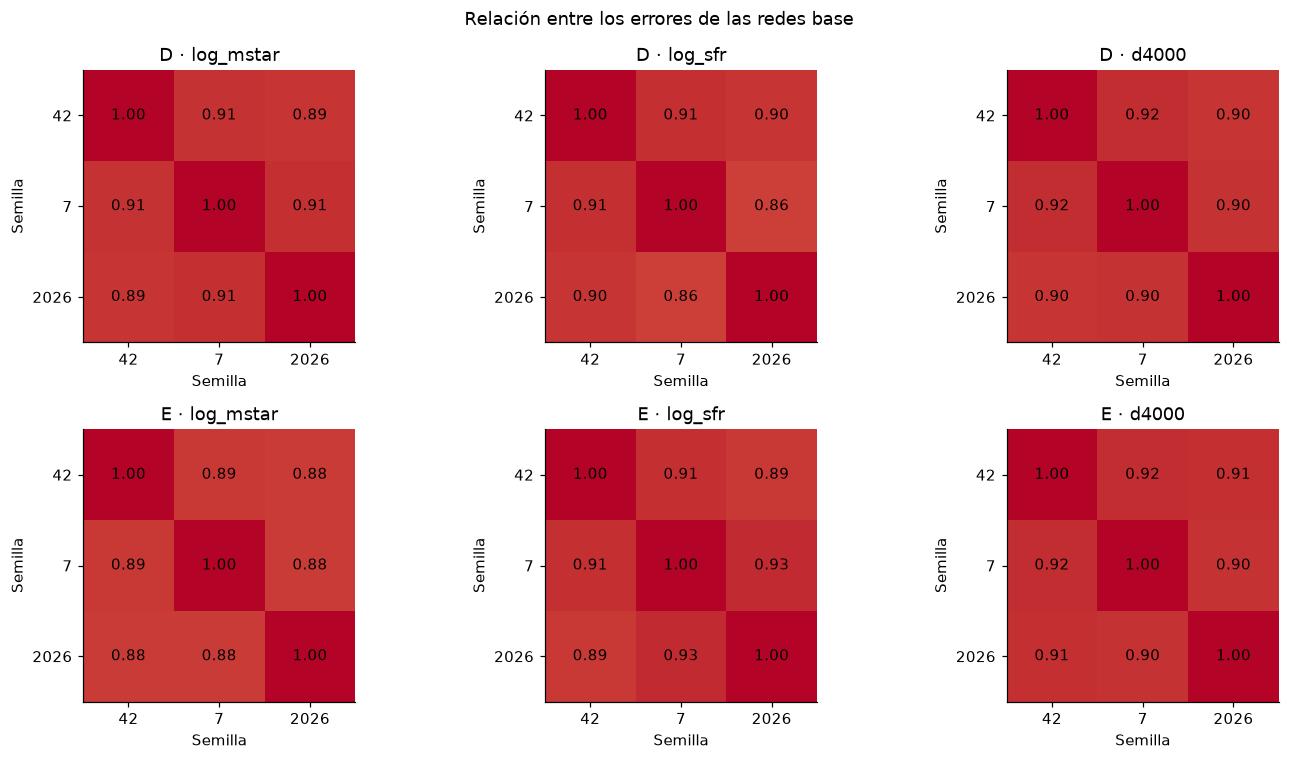

Examinamos si las semillas cometen errores parecidos. Una correlación cercana a uno indica que las redes fallan de forma similar y puede limitar el beneficio de promediarlas. La mejora efectiva la determinamos con las métricas del ensamble.

In [11]:
DIVERSIDAD = []
fig, ejes = plt.subplots(2, 3, figsize=(13, 7))
for fila, letra in enumerate(['D','E']):
    residuos = PREDICCIONES[letra] - Y[:, None, :]
    for j, objetivo in enumerate(OBJETIVOS):
        corr = pd.DataFrame(residuos[:, :, j]).corr().to_numpy()
        eje = ejes[fila,j]; eje.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
        for a in range(3):
            for b in range(3): eje.text(b,a,f'{corr[a,b]:.2f}',ha='center',va='center',fontsize=10)
        eje.set(xticks=range(3), yticks=range(3), xticklabels=SEMILLAS, yticklabels=SEMILLAS,
                title=f'{letra} · {objetivo}', xlabel='Semilla', ylabel='Semilla')
        for a,b in itertools.combinations(range(3),2):
            DIVERSIDAD.append({'variante':letra,'objetivo':objetivo,'semilla_1':SEMILLAS[a],
                              'semilla_2':SEMILLAS[b],'correlacion_residuos':corr[a,b]})
fig.suptitle('Relación entre los errores de las redes base'); fig.tight_layout()
fig.savefig(SALIDA / 'diversidad_residuos.png', bbox_inches='tight')
plt.show(); plt.close(fig)
DIVERSIDAD = pd.DataFrame(DIVERSIDAD)
guardar_csv(DIVERSIDAD, SALIDA / 'correlacion_residuos.csv')
display(Markdown('Examinamos si las semillas cometen errores parecidos. Una correlación cercana a uno '
                 'indica que las redes fallan de forma similar y puede limitar el beneficio de promediarlas. '
                 'La mejora efectiva la determinamos con las métricas del ensamble.'))


## 10. Diferencia de error frente a ResNet50_E_s42

Calculamos por galaxia la diferencia de MSE normalizado entre cada ensamble y el modelo individual. Remuestreamos galaxias de forma pareada para conservar la correspondencia entre sus predicciones. Una diferencia negativa favorece al ensamble; una positiva favorece al individual.

Los percentiles 2.5 y 97.5 describen la dispersión de esa diferencia con las predicciones ya obtenidas. No reentrenamos las redes ni repetimos la búsqueda de pesos en cada remuestreo, de modo que este diagnóstico no incorpora toda la incertidumbre de selección y entrenamiento.

In [12]:
def contraste_pareado(y, pred, referencia, escala, repeticiones, semilla):
    if not isinstance(repeticiones, int) or repeticiones < 100:
        raise ValueError('Usamos al menos 100 remuestreos para el diagnóstico.')
    delta = np.mean(((pred-y)/escala)**2 - ((referencia-y)/escala)**2, axis=1)
    rng = np.random.default_rng(semilla)
    simulados = np.array([delta[rng.integers(0, len(delta), len(delta))].mean() for _ in range(repeticiones)])
    return {'delta_MSE_normalizado': float(delta.mean()),
            'percentil_2_5': float(np.quantile(simulados,.025)), 'percentil_97_5': float(np.quantile(simulados,.975))}

CONTRASTES = pd.DataFrame([{'modelo':nombre, **contraste_pareado(Y,p,PRED_COMPARACION[BASE_INDIVIDUAL],ESCALA_TRAIN,
                                       CFG['bootstrap_repeticiones'],CFG['semilla_bootstrap'])}
                          for nombre,p in PRED_COMPARACION.items() if nombre != BASE_INDIVIDUAL])
display(CONTRASTES)
guardar_csv(CONTRASTES,SALIDA/'contrastes_pareados.csv')


,modelo,delta_MSE_normalizado,percentil_2_5,percentil_97_5
0,Ensamble_ResNet50_D,-0.008454,-0.012161,-0.004453
1,Ensamble_ResNet50_E,-0.009277,-0.013143,-0.005127


## 11. Cuatro gráficos del candidato elegido

Analizamos el candidato que ocupa el primer lugar en nuestra comparación local, aunque sea el modelo individual. Generamos cuatro figuras, cada una con paneles para masa, SFR y D4000:

1. Referencias frente a predicciones, para observar la concordancia y los errores a lo largo de cada propiedad.
2. Distribución de residuos, para revisar sesgo, dispersión y colas.
3. Residuos frente al valor de referencia, para identificar regiones de sobreestimación o subestimación.
4. Residuos frente al redshift, para explorar cómo cambia el error con esta variable.

Calculamos los valores de las interpretaciones a partir de las predicciones reales. Utilizamos gráficos de regresión porque nuestras salidas son propiedades continuas; los ejemplos de ROC y matrices de confusión corresponden a tareas de clasificación.

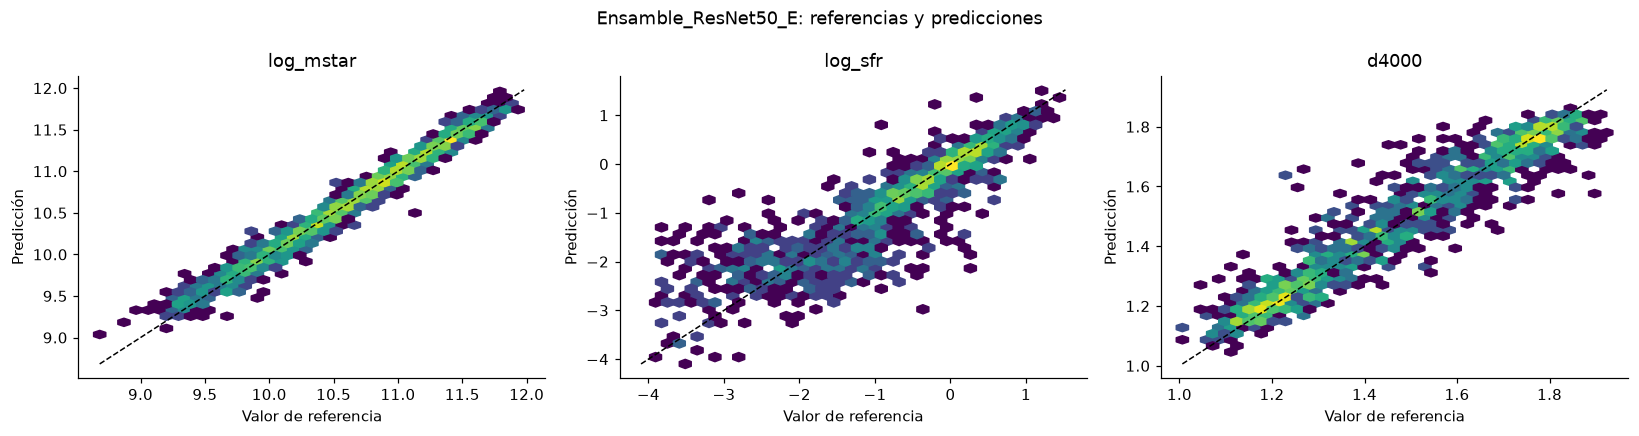

Comparamos las predicciones con la diagonal de coincidencia. Para log_mstar obtuvimos R² = 0.9748 y RMSE = 0.1040 dex. Para log_sfr obtuvimos R² = 0.7573 y RMSE = 0.5732 dex. Para d4000 obtuvimos R² = 0.9084 y RMSE = 0.0713 adimensional. La dispersión alrededor de la diagonal muestra el error por galaxia; las métricas incluyen todos los objetos.

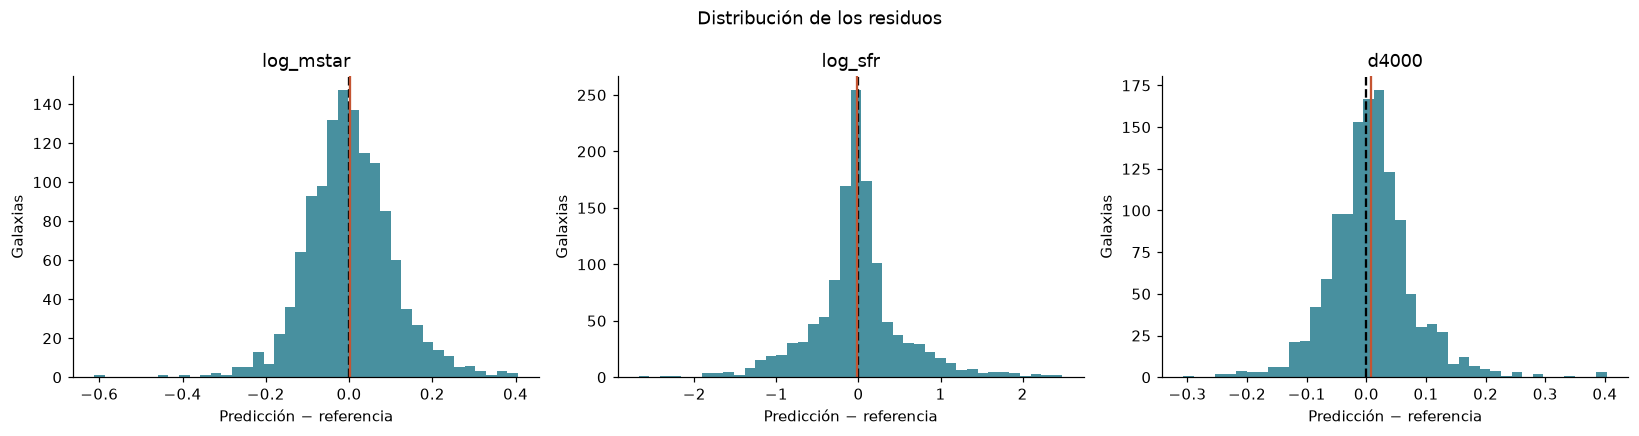

Revisamos el desplazamiento y la amplitud de los errores. En log_mstar, el sesgo fue +0.0029 y el intervalo central del 68 % fue [-0.0928, +0.0955]. En log_sfr, el sesgo fue -0.0146 y el intervalo central del 68 % fue [-0.4407, +0.3694]. En d4000, el sesgo fue +0.0077 y el intervalo central del 68 % fue [-0.0518, +0.0617]. Un sesgo positivo indica sobreestimación media y uno negativo, subestimación; las colas muestran los errores más grandes.

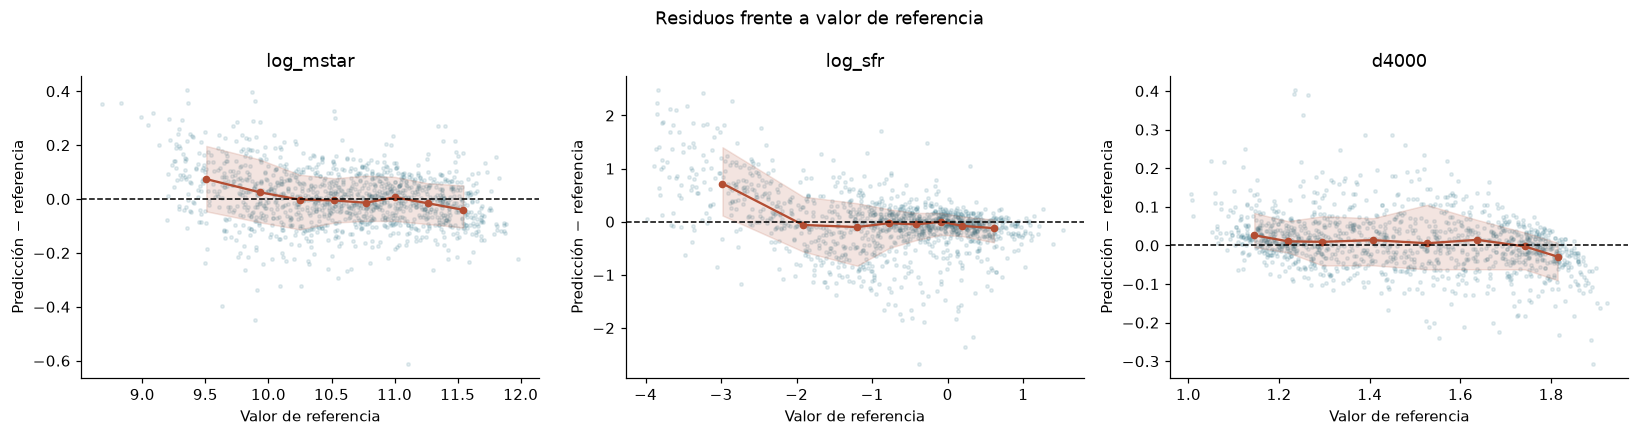

En log_mstar, la mayor mediana absoluta de residuo entre intervalos fue +0.0738, alrededor de valor de referencia = 9.5077 (n = 158). En log_sfr, la mayor mediana absoluta de residuo entre intervalos fue +0.7194, alrededor de valor de referencia = -2.9817 (n = 158). En d4000, la mayor mediana absoluta de residuo entre intervalos fue -0.0291, alrededor de valor de referencia = 1.8142 (n = 158). La línea resume la mediana y la franja el 68 % central de los residuos; no representa un intervalo de confianza de la mediana. Buscamos cambios sistemáticos del error a lo largo de cada propiedad.

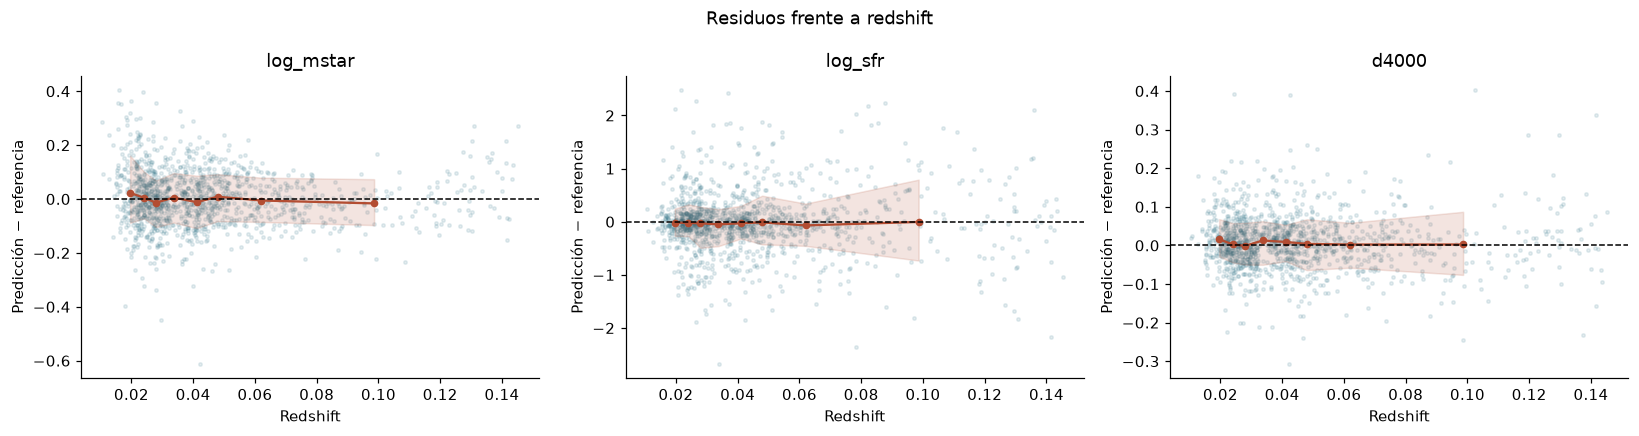

En log_mstar, la mayor mediana absoluta de residuo entre intervalos fue +0.0226, alrededor de redshift = 0.0196 (n = 158). En log_sfr, la mayor mediana absoluta de residuo entre intervalos fue -0.0694, alrededor de redshift = 0.0620 (n = 158). En d4000, la mayor mediana absoluta de residuo entre intervalos fue +0.0158, alrededor de redshift = 0.0196 (n = 158). La línea resume la mediana y la franja el 68 % central de los residuos; no representa un intervalo de confianza de la mediana. Este diagnóstico permite revisar cómo cambia el error con la distancia observacional indicada por el redshift, sin atribuir por sí solo una causa física.

In [13]:
def resumen_por_intervalos(x, residuos, numero=8):
    bordes = np.unique(np.quantile(x, np.linspace(0,1,numero+1)))
    grupos = np.searchsorted(bordes[1:-1], x, side='right')
    filas = []
    for g in np.unique(grupos):
        mascara = grupos == g
        if mascara.sum() >= 3:
            filas.append([np.median(x[mascara]),np.median(residuos[mascara]),
                           *np.quantile(residuos[mascara],[.16,.84]),int(mascara.sum())])
    return np.asarray(filas,float).reshape(-1,5)

PRED_GANADOR = PRED_COMPARACION[GANADOR_LOCAL]
RESIDUOS = PRED_GANADOR - Y
MET_GANADOR = METRICAS.loc[METRICAS.modelo.eq(GANADOR_LOCAL)].set_index('objetivo').reindex(OBJETIVOS)
INTERPRETACIONES = []
FIGURAS = []
def mostrar_guardar(fig, nombre, texto):
    fig.tight_layout()
    fig.savefig(SALIDA / (nombre + '.png'), bbox_inches='tight')
    FIGURAS.append((nombre, fig))
    plt.show()
    INTERPRETACIONES.append({'grafico': nombre, 'interpretacion': texto})
    display(Markdown(texto))

fig,ejes = plt.subplots(1,3,figsize=(15,4))
for j,(eje,objetivo) in enumerate(zip(ejes,OBJETIVOS)):
    limites = [float(min(Y[:,j].min(),PRED_GANADOR[:,j].min())),float(max(Y[:,j].max(),PRED_GANADOR[:,j].max()))]
    eje.hexbin(Y[:,j],PRED_GANADOR[:,j],gridsize=35,mincnt=1,cmap='viridis',bins='log')
    eje.plot(limites,limites,'k--',lw=1)
    eje.set(title=objetivo,xlabel='Valor de referencia',ylabel='Predicción')
fig.suptitle(f'{GANADOR_LOCAL}: referencias y predicciones')
texto = 'Comparamos las predicciones con la diagonal de coincidencia. ' + ' '.join(
    f'Para {o} obtuvimos R² = {MET_GANADOR.loc[o,"R2"]:.4f} y RMSE = {MET_GANADOR.loc[o,"RMSE"]:.4f} '
    f'{"adimensional" if o=="d4000" else "dex"}.' for o in OBJETIVOS)
texto += ' La dispersión alrededor de la diagonal muestra el error por galaxia; las métricas incluyen todos los objetos.'
mostrar_guardar(fig,'01_referencia_prediccion',texto)

fig,ejes=plt.subplots(1,3,figsize=(15,4))
for j,(eje,o) in enumerate(zip(ejes,OBJETIVOS)):
    eje.hist(RESIDUOS[:,j],bins=40,color='#287d8e',alpha=.85)
    eje.axvline(0,color='black',ls='--'); eje.axvline(RESIDUOS[:,j].mean(),color='#c45432')
    eje.set(title=o,xlabel='Predicción − referencia',ylabel='Galaxias')
fig.suptitle('Distribución de los residuos')
texto='Revisamos el desplazamiento y la amplitud de los errores. ' + ' '.join(
    f'En {o}, el sesgo fue {RESIDUOS[:,j].mean():+.4f} y el intervalo central del 68 % fue '
    f'[{np.quantile(RESIDUOS[:,j],.16):+.4f}, {np.quantile(RESIDUOS[:,j],.84):+.4f}].'
    for j,o in enumerate(OBJETIVOS))
texto+=' Un sesgo positivo indica sobreestimación media y uno negativo, subestimación; las colas muestran los errores más grandes.'
mostrar_guardar(fig,'02_distribucion_residuos',texto)

for nombre,xs,etiqueta in [('03_residuos_referencia',Y,'Valor de referencia'),
                          ('04_residuos_redshift',np.tile(VALIDACION.redshift.to_numpy()[:,None],(1,3)),'Redshift')]:
    fig,ejes=plt.subplots(1,3,figsize=(15,4)); descripciones=[]
    for j,(eje,o) in enumerate(zip(ejes,OBJETIVOS)):
        x=xs[:,j]; r=RESIDUOS[:,j]
        eje.scatter(x,r,s=5,alpha=.12,color='#2b7186')
        b=resumen_por_intervalos(x,r)
        if len(b):
            eje.plot(b[:,0],b[:,1],'-o',color='#b34d32',ms=4)
            eje.fill_between(b[:,0],b[:,2],b[:,3],alpha=.15,color='#b34d32')
            k=int(np.argmax(np.abs(b[:,1])))
            descripciones.append(f'En {o}, la mayor mediana absoluta de residuo entre intervalos fue '
                                 f'{b[k,1]:+.4f}, alrededor de {etiqueta.lower()} = {b[k,0]:.4f} (n = {int(b[k,4])}).')
        eje.axhline(0,color='black',ls='--',lw=1)
        eje.set(title=o,xlabel=etiqueta,ylabel='Predicción − referencia')
    fig.suptitle('Residuos frente a '+etiqueta.lower())
    texto=' '.join(descripciones)+' La línea resume la mediana y la franja el 68 % central de los residuos; no representa un intervalo de confianza de la mediana.'
    texto+=(' Buscamos cambios sistemáticos del error a lo largo de cada propiedad.' if nombre.endswith('referencia') else
            ' Este diagnóstico permite revisar cómo cambia el error con la distancia observacional indicada por el redshift, sin atribuir por sí solo una causa física.')
    mostrar_guardar(fig,nombre,texto)

with PdfPages(SALIDA/'graficos_modelo_elegido.pdf') as pdf:
    for nombre,fig in FIGURAS: pdf.savefig(fig,bbox_inches='tight')
for _,fig in FIGURAS: plt.close(fig)
guardar_json(INTERPRETACIONES,SALIDA/'interpretaciones_graficos.json')


## 12. Importancia de las entradas y sensibilidad de las imágenes

Ampliamos la interpretación del candidato que seleccionamos en la comparación local. Evaluamos cuánto depende de las bandas g, r y z y del redshift, y exploramos las regiones de las imágenes que producen cambios en sus predicciones. Conservamos los checkpoints y los pesos de combinación; no volvemos a entrenarlos ni modificamos la elección del ganador.

Primero reconstruimos las predicciones originales a partir de los cubos GRZ guardados y de los checkpoints `multitarea/mejor.pt`. Comprobamos que coinciden con los CSV antes de interpretar los cambios. Recuperamos la transformación asinh, la estandarización de las bandas y del redshift y la escala de las etiquetas a partir de `estadisticos_Train.json`.

Para los ensambles conservamos los pesos que correspondían al pliegue externo de cada galaxia. Así interpretamos las mismas predicciones evaluadas en la comparación, en lugar de sustituirlas por las del ajuste final realizado con toda Validation. Durante las perturbaciones mantenemos esos pesos fijos y utilizamos la misma modificación en todas las redes.

Estas secciones necesitan las imágenes indicadas en `muestra_lista.csv`, los checkpoints del candidato elegido y el kernel de PyTorch y torchvision del entrenamiento A–G. Aprovechamos CUDA cuando está disponible. Trabajamos exclusivamente con galaxias de Validation y registramos los tiempos de interpretación por separado del entrenamiento.

### 12.1. Parámetros del análisis

Definimos los siguientes parámetros antes de observar los mapas o las importancias. Son decisiones del análisis de sensibilidad, no hiperparámetros elegidos por mejorar el resultado del modelo.

| Parámetro | Valor | Motivo |
|---|---|---|
| Galaxias para permutación | 256, elegidas al azar con semilla 31415 | Mantenemos una muestra reproducible y un costo de inferencia acotado. Podemos usar toda Validation indicando `n_permutacion=None`. |
| Repeticiones | 20 | Medimos la variabilidad del efecto al cambiar la asignación de las entradas entre galaxias. |
| Entradas alteradas | g, r, z, redshift y GRZ conjunto | Estudiamos las cuatro entradas individuales y añadimos un control que conserva juntas las tres bandas de cada imagen. |
| Galaxias para oclusión | Seis, distribuidas entre los percentiles 5 y 95 de masa | Mostramos ejemplos de distintas masas sin seleccionarlos según el error del modelo. No usamos estos seis objetos para estimar una importancia poblacional. |
| Ventanas de oclusión | 30 y 60 píxeles | Contrastamos una región menor y otra mayor sobre la entrada de 300 × 300 píxeles. Conservamos ambos resultados, sin elegir la ventana que produzca el mapa más llamativo. |
| Paso de las ventanas | 30 píxeles | Cubrimos toda la imagen y permitimos solapamiento con la ventana de 60 píxeles. |
| Referencia para oclusión | Mediana de una franja exterior de 30 píxeles por banda, con recorte de 3 dispersiones MAD y hasta cuatro iteraciones | Reducimos el efecto de píxeles extremos sin asumir que cero en la imagen normalizada representa el fondo. |
| Tamaño de lote | 16 | Mantenemos un tamaño conocido del entrenamiento y procesamos una red a la vez para limitar el uso de memoria. |
| Diferencia máxima respecto al CSV | 0.002 en unidades de la desviación de Train | Permitimos como máximo 0.2 % de esa dispersión en cualquier objeto y propiedad. Este control no se usa por sí solo. |
| RMSE de la diferencia respecto al CSV | Hasta 0.0005 en unidades de la desviación de Train | Exigimos que el conjunto de discrepancias sea pequeño, aunque algún objeto esté cerca del límite máximo. |
| Sesgo de la diferencia respecto al CSV | Valor absoluto de hasta 0.0002 en unidades de la desviación de Train | Rechazamos desplazamientos sistemáticos entre las dos inferencias. |
| Cambio relativo en el MSE por propiedad | Hasta 0.005, equivalente a 0.5 % | Comprobamos que la discrepancia también tenga un efecto pequeño sobre el error respecto a las etiquetas. |

Guardamos cada predicción intermedia con una verificación de integridad. Si reiniciamos el kernel y ejecutamos de nuevo, reutilizamos los cálculos completos de la misma configuración. La muestra de permutación se mantiene fija para comparar el error original y el alterado; no comparamos su error con el obtenido sobre las 1,261 galaxias completas.

Utilizamos parámetros e inferencia en float32, con autocast desactivado. Registramos también las opciones TF32 del entorno. Comprobamos todos los límites anteriores por propiedad antes de ejecutar las perturbaciones; guardamos el diagnóstico incluso si una red no los cumple. Una discrepancia aceptada por estos límites no demuestra por sí sola que su causa sea exclusivamente numérica. La versión de este análisis genera su propia carpeta de caché para no reutilizar cálculos de otra implementación.

In [14]:
# Interpretamos el candidato elegido; no cambiamos la selección ni volvemos a ajustar sus pesos.
CFG_INTERP = {
    'n_permutacion': 256,       # None utiliza todas las galaxias de Validation.
    'repeticiones': 20,
    'semilla': 31415,
    'n_occlusion': 6,
    'ventanas_px': [30, 60],
    'paso_px': 30,
    'borde_fondo_px': 30,
    'recorte_mad': 3.0,
    'iteraciones_fondo': 4,
    'batch_size': 16,
    'dispositivo': 'auto',     # CUDA cuando está disponible; también admite 'cpu' o 'cuda'.
    'raiz_cache': '',          # Solo si trasladamos los .npy a otra carpeta.
    'tolerancia_reproduccion_normalizada': 0.002,
    'tolerancia_rmse_diferencia_normalizada': 0.0005,
    'tolerancia_sesgo_diferencia_normalizada': 0.0002,
    'tolerancia_cambio_mse_relativo': 0.005,
}
VERSION_INTERP = 'PERMUTACION_OCLUSION_GRZ_1.0.1'
GRUPOS_INTERP = ['g', 'r', 'z', 'redshift', 'GRZ_conjunto']
IMPLEMENTACION_INTERP_SHA = '76d0096afe5adcc1accecbdc45f6056a82ddd712104e69c1d62598b22d079abe'


In [15]:
def interp_indices(n, cfg, masa):
    cantidad = n if cfg['n_permutacion'] is None else cfg['n_permutacion']
    if not isinstance(cantidad, int) or not 2 <= cantidad <= n:
        raise ValueError('n_permutacion debe estar entre 2 y el tamaño de Validation, o ser None.')
    if not isinstance(cfg['n_occlusion'], int) or not 1 <= cfg['n_occlusion'] <= n:
        raise ValueError('n_occlusion no es válido.')
    perm = np.sort(np.random.default_rng(cfg['semilla']).choice(n, cantidad, replace=False))
    orden = np.argsort(np.asarray(masa), kind='stable')
    posiciones = np.rint(np.linspace(0.05, 0.95, cfg['n_occlusion']) * (n-1)).astype(int)
    ocl = orden[posiciones]
    return perm, ocl

def interp_pesos(nombre, resultados, corridas, n):
    if nombre == BASE_INDIVIDUAL:
        miembros = corridas.loc[corridas.modelo.eq(nombre)].copy()
        if len(miembros) != 1: raise ValueError('No encontramos la corrida individual elegida.')
        return miembros.reset_index(drop=True), np.ones((n, 1, 3))
    letra = nombre.rsplit('_', 1)[-1]
    if letra not in resultados or resultados[letra]['nombre'] != nombre:
        raise ValueError('No reconocemos el candidato elegido para interpretación.')
    miembros = corridas.loc[corridas.variante.eq(letra)].set_index('semilla').loc[SEMILLAS].reset_index()
    r = resultados[letra]
    pl = np.asarray(r['pliegues'])
    if pl.shape != (n,): raise ValueError('Los pliegues no coinciden con Validation.')
    w = np.full((n, len(SEMILLAS), 3), np.nan)
    for d in r['pesos_pliegues']:
        w[pl == d['pliegue']] = np.asarray(d['pesos'], float)
    if not np.isfinite(w).all() or np.any(w < -1e-10) or not np.allclose(w.sum(axis=1), 1):
        raise ValueError('Los pesos por galaxia no son válidos.')
    return miembros, w

def interp_transformar(cubos, stats):
    a = np.asarray(cubos, dtype=np.float64)
    escala = np.asarray(stats['asinh_escala'], float).reshape(1,3,1,1)
    media = np.asarray(stats['grz_media'], float).reshape(1,3,1,1)
    desvio = np.asarray(stats['grz_std'], float).reshape(1,3,1,1)
    if a.ndim != 4 or a.shape[1] != 3 or not np.isfinite(a).all():
        raise ValueError('Esperamos cubos GRZ finitos con dimensiones (N,3,H,W).')
    if not np.isfinite(np.r_[escala.ravel(),media.ravel(),desvio.ravel()]).all() or np.any(escala <= 0) or np.any(desvio <= 0):
        raise ValueError('Estadísticos GRZ no válidos.')
    return np.ascontiguousarray((np.arcsinh(a/escala)-media)/desvio, dtype=np.float32)

def interp_fondo(cubo, cfg):
    _, alto, ancho = cubo.shape
    b = cfg['borde_fondo_px']
    if not isinstance(b,int) or not 1 <= b < min(alto,ancho)/2:
        raise ValueError('La franja de referencia debe ser menor que la mitad de la imagen.')
    mascara = np.ones((alto,ancho), bool); mascara[b:-b,b:-b] = False
    medias, detalles = [], []
    for j,banda in enumerate('grz'):
        valores = np.asarray(cubo[j][mascara],float)
        for _ in range(cfg['iteraciones_fondo']):
            mediana = np.median(valores)
            sigma = 1.4826*np.median(np.abs(valores-mediana))
            if sigma <= 0: break
            conservar = np.abs(valores-mediana) <= cfg['recorte_mad']*sigma
            if conservar.all() or conservar.sum() < 10: break
            valores = valores[conservar]
        mediana = float(np.median(valores))
        medias.append(mediana)
        detalles.append({'banda':banda,'mediana_referencia':mediana,
                         'sigma_MAD':float(1.4826*np.median(np.abs(valores-mediana))),
                         'pixeles_conservados':len(valores),'pixeles_franja':int(mascara.sum())})
    return np.asarray(medias), detalles

def interp_parches(alto, ancho, ventana, paso):
    if not 1 <= paso <= ventana <= min(alto,ancho):
        raise ValueError('Necesitamos paso <= ventana <= lado de la imagen.')
    def origenes(lado):
        return sorted(set([*range(0,lado-ventana+1,paso),lado-ventana]))
    return [(y,y+ventana,x,x+ventana) for y in origenes(alto) for x in origenes(ancho)]

def interp_mapa(parches, diferencias, alto, ancho):
    total = np.zeros((3,alto,ancho),float); cuentas = np.zeros((alto,ancho),int)
    for (y0,y1,x0,x1), delta in zip(parches,diferencias):
        total[:,y0:y1,x0:x1] += np.asarray(delta)[:,None,None]
        cuentas[y0:y1,x0:x1] += 1
    if np.any(cuentas == 0): raise ValueError('Hay píxeles sin cubrir por las ventanas de oclusión.')
    return total/cuentas[None,:,:], cuentas

def interp_permutar(predictor, imagenes, z, permutacion, grupo, lote):
    n = len(z); salida = np.empty((n,3),float)
    p = np.asarray(permutacion)
    if sorted(p.tolist()) != list(range(n)): raise ValueError('Permutación inválida.')
    if grupo not in GRUPOS_INTERP: raise ValueError('Entrada no reconocida.')
    for inicio in range(0,n,lote):
        fin = min(inicio+lote,n)
        x = imagenes[inicio:fin].copy(); zz = z[inicio:fin].copy()
        donantes = p[inicio:fin]
        if grupo == 'redshift': zz = z[donantes].copy()
        elif grupo == 'GRZ_conjunto': x = imagenes[donantes].copy()
        else:
            banda = 'grz'.index(grupo)
            x[:,banda] = imagenes[donantes,banda]
        salida[inicio:fin] = predictor(x,zz)
    return salida

def interp_ocluir(predictor, imagen, z, referencia, parches, lote):
    salida = np.empty((len(parches),3),float)
    for inicio in range(0,len(parches),lote):
        grupo = parches[inicio:inicio+lote]
        x = np.repeat(imagen[None],len(grupo),axis=0)
        for k,(y0,y1,x0,x1) in enumerate(grupo):
            x[k,:,y0:y1,x0:x1] = referencia[:,None,None]
        salida[inicio:inicio+len(grupo)] = predictor(x,np.full(len(grupo),z))
    return salida

class ErrorReproduccionInterpretacion(RuntimeError):
    def __init__(self,mensaje,diagnostico):
        super().__init__(mensaje)
        self.diagnostico=diagnostico

def interp_reproducir(actual, referencia, escala, tolerancia, etiquetas=None, cfg=None):
    actual,referencia,escala=map(lambda x:np.asarray(x,float),(actual,referencia,escala))
    if (actual.shape != referencia.shape or actual.ndim != 2 or actual.shape[1] != 3
        or len(actual)==0 or escala.shape != (3,) or np.any(escala <= 0)
        or not np.isfinite(actual).all() or not np.isfinite(referencia).all() or not np.isfinite(escala).all()):
        raise ValueError('Dimensiones o valores inválidos en la inferencia reconstruida.')
    cfg=CFG_INTERP if cfg is None else cfg
    limites={'max':float(tolerancia),'rmse':float(cfg['tolerancia_rmse_diferencia_normalizada']),
             'sesgo':float(cfg['tolerancia_sesgo_diferencia_normalizada']),
             'mse':float(cfg['tolerancia_cambio_mse_relativo'])}
    if not np.isfinite(list(limites.values())).all() or min(limites.values()) <= 0:
        raise ValueError('Los límites de reproducción deben ser finitos y positivos.')
    diferencia = (actual-referencia)/escala
    if etiquetas is not None:
        etiquetas=np.asarray(etiquetas,float)
        if etiquetas.shape != actual.shape or not np.isfinite(etiquetas).all():
            raise ValueError('Las etiquetas de la comprobación no coinciden con las predicciones.')
    filas=[];problemas=[]
    for j,obj in enumerate(OBJETIVOS):
        d=diferencia[:,j]; maximo=float(np.max(np.abs(d)))
        rmse=float(np.sqrt(np.mean(d*d))); sesgo=float(np.mean(d))
        cambio=None; mse_ref=None; mse_actual=None
        comprobaciones={'maximo':maximo <= limites['max'], 'RMSE':rmse <= limites['rmse'],
                        'sesgo':abs(sesgo) <= limites['sesgo']}
        if etiquetas is not None:
            mse_ref=float(np.mean(((referencia[:,j]-etiquetas[:,j])/escala[j])**2))
            mse_actual=float(np.mean(((actual[:,j]-etiquetas[:,j])/escala[j])**2))
            cambio=float(abs(mse_actual-mse_ref)/max(mse_ref,1e-12))
            comprobaciones['cambio_MSE']=cambio <= limites['mse']
        ok=bool(all(comprobaciones.values()))
        filas.append({'objetivo':obj,'max_diferencia_normalizada':maximo,
            'p99_diferencia_normalizada':float(np.quantile(np.abs(d),.99)),
            'RMSE_diferencia_normalizada':rmse,'sesgo_diferencia_normalizada':sesgo,
            'max_diferencia_unidad_original':float(np.max(np.abs(actual[:,j]-referencia[:,j]))),
            'MSE_normalizado_CSV':mse_ref,'MSE_normalizado_recalculado':mse_actual,
            'cambio_MSE_relativo':cambio,'aceptado':ok})
        if not ok:
            problemas.append(obj+': '+', '.join(k for k,v in comprobaciones.items() if not v))
    diagnostico={'max_diferencia_normalizada':float(np.max(np.abs(diferencia))),
                'RMSE_diferencia_normalizada':float(np.sqrt(np.mean(diferencia**2))),
                'aceptado':not problemas,'por_objetivo':filas,'limites':limites}
    if problemas:
        raise ErrorReproduccionInterpretacion('No continuamos la interpretación porque la diferencia con los CSV '
            'supera estos controles: '+'; '.join(problemas)+'. Se guarda el diagnóstico por propiedad; '
            'el error no identifica por sí solo si la causa es precisión, preprocesamiento u otra diferencia.',diagnostico)
    return diagnostico

def interp_cache(ruta, forma, calcular):
    ruta = Path(ruta); sello = ruta.with_suffix('.json')
    if ruta.exists():
        if not sello.is_file() or json.loads(sello.read_text()).get('sha256') != hash_archivo(ruta):
            raise RuntimeError('Caché incompleta o alterada: '+str(ruta))
        a = np.load(ruta,allow_pickle=False)
    else:
        a = np.asarray(calcular(),float)
        if a.shape != tuple(forma) or not np.isfinite(a).all(): raise ValueError('Resultado de interpretación no válido.')
        temporal = ruta.with_name(ruta.name+f'.{os.getpid()}.tmp')
        with temporal.open('wb') as f: np.save(f,a,allow_pickle=False)
        os.replace(temporal,ruta)
        guardar_json({'sha256':hash_archivo(ruta),'forma':list(a.shape)},sello)
    if a.shape != tuple(forma) or not np.isfinite(a).all(): raise ValueError('Dimensiones o valores de caché incorrectos.')
    return a


In [16]:
def interp_cargar_red(ruta, dispositivo):
    # Cargamos exclusivamente los parámetros locales. No descargamos pesos ImageNet.
    import torch
    from torch import nn
    from torchvision.models import resnet50
    payload = torch.load(ruta,map_location='cpu',weights_only=True)
    if not isinstance(payload,dict) or not isinstance(payload.get('modelo'),dict):
        raise ValueError('El checkpoint no tiene el formato mejor.pt del experimento A–G.')
    state = payload['modelo']
    for j in range(3):
        for capa,dim in [(0,(256,2049)),(3,(1,256))]:
            clave = f'salidas.{j}.{capa}.weight'
            if clave not in state or tuple(state[clave].shape) != dim:
                raise ValueError('La arquitectura del checkpoint no coincide con ResNet50 GRZ + redshift de A–G: '+clave)
    secuencial = 'backbone.0.weight' in state
    if not secuencial and 'backbone.conv1.weight' not in state:
        raise ValueError('No reconocemos los nombres del extractor en el checkpoint.')
    class RedInterpretacion(nn.Module):
        def __init__(self):
            super().__init__()
            red = resnet50(weights=None)
            if secuencial: self.backbone = nn.Sequential(*list(red.children())[:-1])
            else:
                red.fc = nn.Identity(); self.backbone = red
            self.salidas = nn.ModuleList([nn.Sequential(nn.Linear(2049,256),nn.ReLU(),
                                         nn.Dropout(.1),nn.Linear(256,1)) for _ in range(3)])
        def forward(self,x,z):
            features = self.backbone(x).flatten(1)
            features = torch.cat([features,z.reshape(-1,1)],dim=1)
            return torch.cat([c(features) for c in self.salidas],dim=1)
    with torch.random.fork_rng(devices=[]):
        red = RedInterpretacion()
    red.load_state_dict(state,strict=True)
    red = red.to(device=dispositivo,dtype=torch.float32).eval()
    for p in red.parameters(): p.requires_grad_(False)
    return red

def interp_predictor(red, stats, dispositivo):
    import torch
    zm,zs = float(stats['z_media']),float(stats['z_std'])
    ym,ys = np.asarray(stats['y_media']),np.asarray(stats['y_std'])
    if not np.isfinite([zm,zs]).all() or zs <= 0: raise ValueError('Escala de redshift inválida.')
    def predecir(x,z):
        xx = torch.as_tensor(np.ascontiguousarray(x,dtype=np.float32),device=dispositivo)
        zz = torch.as_tensor(np.ascontiguousarray((np.asarray(z)-zm)/zs,dtype=np.float32),device=dispositivo)
        with torch.inference_mode(), torch.autocast(device_type=dispositivo.type,enabled=False):
            pn = red(xx,zz).detach().float().cpu().numpy()
        return pn.astype(float)*ys+ym
    return predecir


In [17]:
import gc, importlib.util
if CFG['evaluar_test'] is not False:
    raise ValueError('La interpretación solo utiliza Validation.')
faltan_interp = [p for p in ['torch','torchvision'] if importlib.util.find_spec(p) is None]
if faltan_interp:
    raise RuntimeError('Para las nuevas secciones necesitamos el kernel del entrenamiento A–G, con PyTorch y torchvision. '
                       'No reinstalamos sus dependencias automáticamente. Faltan: '+', '.join(faltan_interp))
import torch, torchvision
if CFG_INTERP['dispositivo'] not in ['auto','cpu','cuda']: raise ValueError('Dispositivo no reconocido.')
DISPOSITIVO_INTERP = torch.device('cuda' if CFG_INTERP['dispositivo']=='auto' and torch.cuda.is_available()
                                 else 'cpu' if CFG_INTERP['dispositivo']=='auto' else CFG_INTERP['dispositivo'])
if DISPOSITIVO_INTERP.type=='cuda' and not torch.cuda.is_available(): raise RuntimeError('Este kernel no detecta CUDA.')
if (not isinstance(CFG_INTERP['repeticiones'],int) or CFG_INTERP['repeticiones'] < 2
    or not isinstance(CFG_INTERP['batch_size'],int) or CFG_INTERP['batch_size'] < 1):
    raise ValueError('Necesitamos al menos dos permutaciones y un batch_size positivo.')
if (not CFG_INTERP['ventanas_px'] or len(set(CFG_INTERP['ventanas_px'])) != len(CFG_INTERP['ventanas_px'])
    or CFG_INTERP['recorte_mad'] <= 0 or CFG_INTERP['iteraciones_fondo'] < 1):
    raise ValueError('Revisamos los parámetros de oclusión y referencia.')

RAIZ_INTERP = Path(CFG['carpeta_ag']).expanduser().resolve()
STATS_INTERP = json.loads((RAIZ_INTERP/'estadisticos_Train.json').read_text())
if not np.allclose(STATS_INTERP['y_std'],ESCALA_TRAIN,rtol=1e-10,atol=1e-12):
    raise ValueError('Las escalas de etiquetas cambiaron desde la comparación.')
tabla_cache = pd.read_csv(RAIZ_INTERP/'muestra_lista.csv',dtype={'mangaid':'string'})
if not {'mangaid','particion','ruta_cache','cache_sha256'}.issubset(tabla_cache):
    raise ValueError('muestra_lista.csv debe conservar ruta_cache y cache_sha256 del experimento A–G.')
tabla_cache = tabla_cache.loc[tabla_cache.particion.eq('Validation')].set_index('mangaid')
if tabla_cache.index.duplicated().any() or set(tabla_cache.index) != set(VALIDACION.mangaid):
    raise ValueError('La muestra de imágenes no corresponde exactamente a Validation.')
tabla_cache = tabla_cache.loc[VALIDACION.mangaid].reset_index()
if not np.allclose(tabla_cache[[*OBJETIVOS,'redshift']],VALIDACION[[*OBJETIVOS,'redshift']],rtol=0,atol=1e-6):
    raise ValueError('Las etiquetas o el redshift cambiaron desde la comparación.')
IPERM, IOCL = interp_indices(len(VALIDACION),CFG_INTERP,VALIDACION.log_mstar.to_numpy())
IUNION = np.union1d(IPERM,IOCL)
MIEMBROS_INTERP, PESOS_INTERP = interp_pesos(GANADOR_LOCAL,RESULTADOS,CORRIDAS,len(VALIDACION))
CUBOS_OCL, REFERENCIAS_OCL, DETALLES_FONDO = {}, {}, []
IMAGENES_PERM = np.empty((len(IPERM),3,300,300),np.float32)
IMAGENES_UNION = np.empty((len(IUNION),3,300,300),np.float32)
pos_union = {int(ix):k for k,ix in enumerate(IUNION)}
fuentes_interp = []
for contador,ix in enumerate(IUNION):
    fila = tabla_cache.iloc[ix]
    ruta = Path(str(fila.ruta_cache)).expanduser()
    if not ruta.is_absolute(): ruta = RAIZ_INTERP/ruta
    if not ruta.is_file() and CFG_INTERP['raiz_cache']:
        ruta = Path(CFG_INTERP['raiz_cache']).expanduser()/ruta.name
    if not ruta.is_file(): raise FileNotFoundError('No encontramos el cubo guardado de '+str(fila.mangaid)+': '+str(ruta))
    huella = hash_archivo(ruta)
    if huella != str(fila.cache_sha256): raise ValueError('El cubo no coincide con el registrado: '+str(fila.mangaid))
    cubo = np.load(ruta,allow_pickle=False)
    if cubo.shape != (3,300,300) or not np.isfinite(cubo).all():
        raise ValueError('Esperamos el recorte GRZ original de 3 × 300 × 300: '+str(ruta))
    imagen = interp_transformar(cubo[None],STATS_INTERP)[0]
    IMAGENES_UNION[contador] = imagen
    fuentes_interp.append({'mangaid':str(fila.mangaid),'ruta':str(ruta),'sha256':huella})
    if ix in IOCL:
        CUBOS_OCL[int(ix)] = cubo.copy()
        fondo, detalle = interp_fondo(cubo,CFG_INTERP)
        ref = interp_transformar(fondo.reshape(1,3,1,1),STATS_INTERP)[0,:,0,0]
        REFERENCIAS_OCL[int(ix)] = ref
        DETALLES_FONDO.extend([{'mangaid':str(fila.mangaid),**d} for d in detalle])
IMAGENES_PERM[:] = IMAGENES_UNION[[pos_union[int(i)] for i in IPERM]]
Z_INTERP = VALIDACION.redshift.to_numpy(float)
miembros_doc = []
for fila in MIEMBROS_INTERP.itertuples():
    ruta = Path(fila.checkpoint).expanduser()
    if not ruta.is_file(): raise FileNotFoundError('Falta el checkpoint '+str(ruta))
    sello = ruta.with_suffix('.json')
    if not sello.is_file(): raise FileNotFoundError('Falta el sello del checkpoint: '+str(sello))
    huella = hash_archivo(ruta)
    if json.loads(sello.read_text()).get('sha256') != huella: raise ValueError('Checkpoint alterado: '+str(ruta))
    miembros_doc.append({'modelo':fila.modelo,'semilla':int(fila.semilla),'checkpoint':str(ruta),'sha256':huella})
for ventana in CFG_INTERP['ventanas_px']: interp_parches(300,300,ventana,CFG_INTERP['paso_px'])
PROTOCOLO_INTERP = {'version':VERSION_INTERP,'implementacion_sha256':IMPLEMENTACION_INTERP_SHA,
    'modelo':GANADOR_LOCAL,'configuracion':CFG_INTERP,'objetivos':OBJETIVOS,
    'mangaid_permutacion':VALIDACION.mangaid.iloc[IPERM].tolist(),
    'mangaid_occlusion':VALIDACION.mangaid.iloc[IOCL].tolist(),
    'peso_por_galaxia_sha256':hashlib.sha256(PESOS_INTERP.tobytes()).hexdigest(),
    'pesos_usados':'Pesos externos del combinador para cada galaxia; fijos durante las perturbaciones',
    'stats_sha256':hash_archivo(RAIZ_INTERP/'estadisticos_Train.json'),
    'redes':miembros_doc,'cubos':fuentes_interp,'torch':torch.__version__,
    'torchvision':torchvision.__version__,'dispositivo':str(DISPOSITIVO_INTERP),
    'inferencia':{'parametros':'float32','autocast':False,
        'cuda_matmul_allow_tf32':getattr(getattr(getattr(torch,'backends',None),'cuda',None),'matmul',None).allow_tf32
             if getattr(getattr(getattr(torch,'backends',None),'cuda',None),'matmul',None) is not None else None,
        'cudnn_allow_tf32':getattr(getattr(getattr(torch,'backends',None),'cudnn',None),'allow_tf32',None)},
    'evaluado_en_test':False}
ID_INTERP = hashlib.sha256(serializar(PROTOCOLO_INTERP).encode()).hexdigest()[:16]
SALIDA_INTERP = SALIDA/'interpretabilidad'/ID_INTERP
SALIDA_INTERP.mkdir(parents=True,exist_ok=True)
(SALIDA_INTERP/'cache').mkdir(exist_ok=True)
guardar_json(PROTOCOLO_INTERP,SALIDA_INTERP/'protocolo_interpretabilidad.json')
guardar_csv(pd.DataFrame(DETALLES_FONDO),SALIDA_INTERP/'referencias_occlusion.csv')
print(f'Interpretamos {GANADOR_LOCAL} con {len(MIEMBROS_INTERP)} redes en {DISPOSITIVO_INTERP}.')
print(f'Permutación: {len(IPERM)} galaxias, {CFG_INTERP["repeticiones"]} repeticiones y cinco grupos de entradas.')
print(f'Oclusión: {len(IOCL)} galaxias, ventanas {CFG_INTERP["ventanas_px"]} píxeles.')


Interpretamos Ensamble_ResNet50_E con 3 redes en cuda.
Permutación: 256 galaxias, 20 repeticiones y cinco grupos de entradas.
Oclusión: 6 galaxias, ventanas [30, 60] píxeles.


### 12.2. Inferencia de las entradas modificadas

Para cada repetición intercambiamos una banda completa entre las galaxias seleccionadas, manteniendo las otras bandas y el redshift. En la prueba de redshift intercambiamos únicamente ese valor. En el control GRZ intercambiamos las imágenes completas, conservando la correspondencia entre sus tres bandas. No desordenamos píxeles dentro de una imagen.

Para la oclusión sustituimos la misma región en las tres bandas por la referencia de cada banda y conservamos el redshift. Aplicamos exactamente la misma perturbación a las redes que forman el ensamble. Procesamos una red a la vez y recuperamos sus predicciones en las unidades originales.

Las celdas muestran el avance por red y grupo de entradas. Esta etapa necesita más tiempo que la comparación de CSV porque vuelve a ejecutar las redes; reutilizar los checkpoints evita entrenarlas otra vez.

In [18]:
def ejecutar_interpretabilidad():
    n = len(IPERM); rep = CFG_INTERP['repeticiones']; lote = CFG_INTERP['batch_size']
    rng = np.random.default_rng(CFG_INTERP['semilla']+1)
    permutaciones = [rng.permutation(n) for _ in range(rep)]
    base_union = np.zeros((len(IUNION),3))
    modificadas = np.zeros((len(GRUPOS_INTERP),rep,n,3))
    ocluidas = {(int(ix),v):np.zeros((len(interp_parches(300,300,v,CFG_INTERP['paso_px'])),3))
                for ix in IOCL for v in CFG_INTERP['ventanas_px']}
    verificaciones = []; verificaciones_por_objetivo = []; tiempos = []
    def comprobar(nombre,actual,referencia):
        fallo=None
        try:
            diagnostico=interp_reproducir(actual,referencia,ESCALA_TRAIN,
                CFG_INTERP['tolerancia_reproduccion_normalizada'],etiquetas=Y[IUNION],cfg=CFG_INTERP)
        except ErrorReproduccionInterpretacion as exc:
            diagnostico=exc.diagnostico;fallo=exc
        verificaciones.append({'modelo':nombre,'n':len(IUNION),
            **{k:v for k,v in diagnostico.items() if k not in ['por_objetivo','limites']}})
        verificaciones_por_objetivo.extend([{'modelo':nombre,'n':len(IUNION),**d}
                                           for d in diagnostico['por_objetivo']])
        guardar_csv(pd.DataFrame(verificaciones),SALIDA_INTERP/'verificacion_predicciones.csv')
        guardar_csv(pd.DataFrame(verificaciones_por_objetivo),SALIDA_INTERP/'verificacion_por_objetivo.csv')
        detalle=VALIDACION.iloc[IUNION][['mangaid',*OBJETIVOS]].copy()
        for j,obj in enumerate(OBJETIVOS):
            detalle['pred_CSV_'+obj]=referencia[:,j]
            detalle['pred_recalculada_'+obj]=actual[:,j]
            detalle['diferencia_normalizada_'+obj]=(actual[:,j]-referencia[:,j])/ESCALA_TRAIN[j]
        guardar_csv(detalle,SALIDA_INTERP/f'reproduccion_{nombre}.csv')
        display(pd.DataFrame(diagnostico['por_objetivo'])[['objetivo','max_diferencia_normalizada',
            'RMSE_diferencia_normalizada','sesgo_diferencia_normalizada','cambio_MSE_relativo','aceptado']].round(8))
        if fallo is not None:
            print('Diagnóstico guardado en:',SALIDA_INTERP/'verificacion_por_objetivo.csv',flush=True)
            raise fallo
        print(f'{nombre}: límites de reproducción cumplidos por las tres propiedades.',flush=True)

    # Verificamos todas las redes y su combinación antes de iniciar las perturbaciones costosas.
    for m,fila in enumerate(MIEMBROS_INTERP.itertuples()):
        inicio = time.perf_counter()
        red = interp_cargar_red(Path(fila.checkpoint),DISPOSITIVO_INTERP)
        predictor = interp_predictor(red,STATS_INTERP,DISPOSITIVO_INTERP)
        cache = SALIDA_INTERP/'cache'
        def original():
            return np.concatenate([predictor(IMAGENES_UNION[i:i+lote],Z_INTERP[IUNION[i:i+lote]])
                                   for i in range(0,len(IUNION),lote)])
        base = interp_cache(cache/f'{fila.modelo}_original.npy',(len(IUNION),3),original)
        if GANADOR_LOCAL == BASE_INDIVIDUAL: ref = PRED_COMPARACION[BASE_INDIVIDUAL][IUNION]
        else: ref = PREDICCIONES[fila.variante][IUNION,SEMILLAS.index(int(fila.semilla)),:]
        comprobar(fila.modelo,base,ref)
        base_union += base*PESOS_INTERP[IUNION,m,:]
        tiempos.append({'modelo':fila.modelo,'etapa':'reproduccion',
                        'segundos_ejecucion_interpretabilidad':time.perf_counter()-inicio})
        del predictor,red;gc.collect()
        if DISPOSITIVO_INTERP.type=='cuda':torch.cuda.empty_cache()
    comprobar(GANADOR_LOCAL,base_union,PRED_COMPARACION[GANADOR_LOCAL][IUNION])
    for m,fila in enumerate(MIEMBROS_INTERP.itertuples()):
        inicio=time.perf_counter()
        red=interp_cargar_red(Path(fila.checkpoint),DISPOSITIVO_INTERP)
        predictor=interp_predictor(red,STATS_INTERP,DISPOSITIVO_INTERP)
        cache=SALIDA_INTERP/'cache'
        for g,grupo in enumerate(GRUPOS_INTERP):
            for k,permutacion in enumerate(permutaciones):
                p = interp_cache(cache/f'{fila.modelo}_perm_{grupo}_{k:03d}.npy',(n,3),
                    lambda:interp_permutar(predictor,IMAGENES_PERM,Z_INTERP[IPERM],permutacion,grupo,lote))
                modificadas[g,k] += p*PESOS_INTERP[IPERM,m,:]
            print(f'{fila.modelo}: {grupo}, {rep} permutaciones terminadas.',flush=True)
        for ix in IOCL:
            imagen = IMAGENES_UNION[pos_union[int(ix)]]
            for ventana in CFG_INTERP['ventanas_px']:
                parches = interp_parches(300,300,ventana,CFG_INTERP['paso_px'])
                p = interp_cache(cache/f'{fila.modelo}_ocl_{int(ix):06d}_{ventana:03d}.npy',(len(parches),3),
                    lambda:interp_ocluir(predictor,imagen,Z_INTERP[ix],REFERENCIAS_OCL[int(ix)],parches,lote))
                ocluidas[(int(ix),ventana)] += p*PESOS_INTERP[ix,m,:]
            print(f'{fila.modelo}: oclusión de {VALIDACION.mangaid.iloc[ix]} terminada.',flush=True)
        tiempos.append({'modelo':fila.modelo,'etapa':'perturbaciones',
                        'segundos_ejecucion_interpretabilidad':time.perf_counter()-inicio})
        del predictor,red; gc.collect()
        if DISPOSITIVO_INTERP.type=='cuda': torch.cuda.empty_cache()
    guardar_csv(pd.DataFrame(tiempos),SALIDA_INTERP/'tiempos_interpretabilidad.csv')
    return base_union,modificadas,ocluidas

BASE_INTERP, PERMUTADAS_INTERP, OCLUIDAS_INTERP = ejecutar_interpretabilidad()


,objetivo,max_diferencia_normalizada,RMSE_diferencia_normalizada,sesgo_diferencia_normalizada,cambio_MSE_relativo,aceptado
0,log_mstar,0.000271,0.000080,0.000002,0.000037,True
1,log_sfr,0.000978,0.000213,-0.000002,0.000006,True
2,d4000,0.000634,0.000141,0.000002,0.000086,True


ResNet50_E_s42: límites de reproducción cumplidos por las tres propiedades.


,objetivo,max_diferencia_normalizada,RMSE_diferencia_normalizada,sesgo_diferencia_normalizada,cambio_MSE_relativo,aceptado
0,log_mstar,0.000261,0.000073,0.000002,0.000092,True
1,log_sfr,0.001386,0.000239,0.000003,0.000046,True
2,d4000,0.000515,0.000130,0.000002,0.000012,True


ResNet50_E_s7: límites de reproducción cumplidos por las tres propiedades.


,objetivo,max_diferencia_normalizada,RMSE_diferencia_normalizada,sesgo_diferencia_normalizada,cambio_MSE_relativo,aceptado
0,log_mstar,0.000346,0.000076,0.000002,0.000039,True
1,log_sfr,0.001416,0.000196,0.000009,0.000001,True
2,d4000,0.000727,0.000129,-0.000015,0.000114,True


ResNet50_E_s2026: límites de reproducción cumplidos por las tres propiedades.


,objetivo,max_diferencia_normalizada,RMSE_diferencia_normalizada,sesgo_diferencia_normalizada,cambio_MSE_relativo,aceptado
0,log_mstar,0.000184,0.000041,0.000002,0.000009,True
1,log_sfr,0.000700,0.000124,0.000004,0.000002,True
2,d4000,0.000292,0.000077,-0.000003,0.000062,True


Ensamble_ResNet50_E: límites de reproducción cumplidos por las tres propiedades.
ResNet50_E_s42: g, 20 permutaciones terminadas.
ResNet50_E_s42: r, 20 permutaciones terminadas.
ResNet50_E_s42: z, 20 permutaciones terminadas.
ResNet50_E_s42: redshift, 20 permutaciones terminadas.
ResNet50_E_s42: GRZ_conjunto, 20 permutaciones terminadas.
ResNet50_E_s42: oclusión de 1-61557 terminada.
ResNet50_E_s42: oclusión de 1-385455 terminada.
ResNet50_E_s42: oclusión de 1-115650 terminada.
ResNet50_E_s42: oclusión de 1-365011 terminada.
ResNet50_E_s42: oclusión de 1-232100 terminada.
ResNet50_E_s42: oclusión de 1-319400 terminada.
ResNet50_E_s7: g, 20 permutaciones terminadas.
ResNet50_E_s7: r, 20 permutaciones terminadas.
ResNet50_E_s7: z, 20 permutaciones terminadas.
ResNet50_E_s7: redshift, 20 permutaciones terminadas.
ResNet50_E_s7: GRZ_conjunto, 20 permutaciones terminadas.
ResNet50_E_s7: oclusión de 1-61557 terminada.
ResNet50_E_s7: oclusión de 1-385455 terminada.
ResNet50_E_s7: oclusión de 1

### 12.3. Gráfico de importancia de las entradas

Definimos la importancia como el aumento del MSE normalizado después de permutar una entrada. Un incremento positivo indica que romper su correspondencia con la galaxia empeoró la predicción. Un valor próximo a cero indica poco cambio bajo esta prueba; un valor negativo indica que la perturbación redujo el error observado y debe interpretarse junto con su variabilidad.

Presentamos un panel para cada propiedad y otro para el criterio global. Las barras muestran el aumento medio y una desviación estándar entre las veinte permutaciones. Estas dispersiones describen la aleatoriedad de la permutación en la muestra fija, no un intervalo de confianza sobre todas las galaxias.

Las bandas y el redshift contienen información relacionada. Intercambiar una sola banda puede crear combinaciones poco realistas, y la información compartida puede reducir la importancia medida de una entrada. Por eso incluimos el control GRZ conjunto y presentamos los resultados como dependencia del modelo respecto de sus entradas, no como porcentajes de contribución ni como evidencia de causalidad física.

,entrada,objetivo,importancia_media,desviacion_permutaciones,minimo,maximo,n
0,GRZ_conjunto,d4000,1.753289,0.105717,1.599033,2.020800,256
1,GRZ_conjunto,global,1.481905,0.080288,1.388691,1.652087,256
2,GRZ_conjunto,log_mstar,0.721889,0.046877,0.638216,0.809417,256
3,GRZ_conjunto,log_sfr,1.970535,0.153756,1.724965,2.313056,256
4,g,d4000,0.984757,0.054032,0.880221,1.104229,256
5,g,global,0.725809,0.033897,0.665711,0.793531,256
6,g,log_mstar,0.088754,0.005842,0.074550,0.099330,256
7,g,log_sfr,1.103915,0.066760,0.972829,1.206188,256
8,r,d4000,0.529377,0.048344,0.434510,0.648721,256
9,r,global,0.488006,0.033073,0.421732,0.558319,256


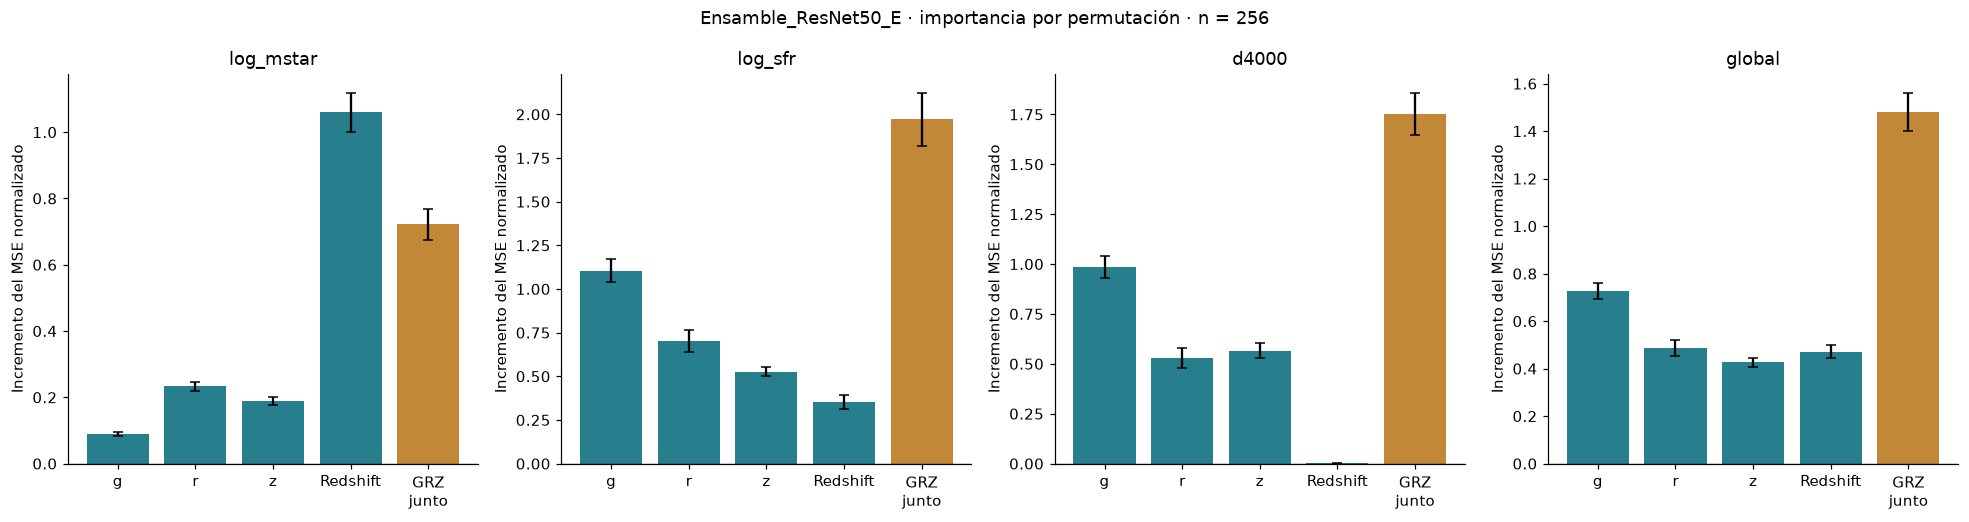

Evaluamos la dependencia del candidato elegido con una muestra fija de 256 galaxias de Validation. Para log_mstar, la mayor degradación media entre las cuatro entradas individuales correspondió a redshift: ΔMSE normalizado = 1.060010 ± 0.059216. Para log_sfr, la mayor degradación media entre las cuatro entradas individuales correspondió a g: ΔMSE normalizado = 1.103915 ± 0.066760. Para d4000, la mayor degradación media entre las cuatro entradas individuales correspondió a g: ΔMSE normalizado = 0.984757 ± 0.054032. Para global, la mayor degradación media entre las cuatro entradas individuales correspondió a g: ΔMSE normalizado = 0.725809 ± 0.033897. Las barras de error representan una desviación estándar entre permutaciones, no un intervalo de confianza poblacional. El control GRZ conjunto mantiene las tres bandas de cada imagen unidas. No interpretamos estas importancias como porcentajes ni como efectos físicos causales.

In [19]:
base_perm = BASE_INTERP[[pos_union[int(i)] for i in IPERM]]
etiquetas_perm = Y[IPERM]
error_base = np.mean(((base_perm-etiquetas_perm)/ESCALA_TRAIN)**2,axis=0)
filas_importancia = []
for g,grupo in enumerate(GRUPOS_INTERP):
    for repeticion in range(CFG_INTERP['repeticiones']):
        error = np.mean(((PERMUTADAS_INTERP[g,repeticion]-etiquetas_perm)/ESCALA_TRAIN)**2,axis=0)
        for j,obj in enumerate(OBJETIVOS):
            filas_importancia.append({'entrada':grupo,'repeticion':repeticion+1,'objetivo':obj,'n':len(IPERM),
                'MSE_original':error_base[j],'MSE_permutado':error[j],'incremento_MSE_normalizado':error[j]-error_base[j]})
        filas_importancia.append({'entrada':grupo,'repeticion':repeticion+1,'objetivo':'global','n':len(IPERM),
            'MSE_original':error_base.mean(),'MSE_permutado':error.mean(),'incremento_MSE_normalizado':(error-error_base).mean()})
IMPORTANCIA_REPETICIONES = pd.DataFrame(filas_importancia)
IMPORTANCIA_ENTRADAS = IMPORTANCIA_REPETICIONES.groupby(['entrada','objetivo'],as_index=False).agg(
    importancia_media=('incremento_MSE_normalizado','mean'),
    desviacion_permutaciones=('incremento_MSE_normalizado','std'),
    minimo=('incremento_MSE_normalizado','min'),maximo=('incremento_MSE_normalizado','max'),n=('n','first'))
guardar_csv(IMPORTANCIA_REPETICIONES,SALIDA_INTERP/'importancia_por_repeticion.csv')
guardar_csv(IMPORTANCIA_ENTRADAS,SALIDA_INTERP/'importancia_entradas.csv')
guardar_csv(VALIDACION.iloc[IPERM][['mangaid','particion',*OBJETIVOS,'redshift']],SALIDA_INTERP/'muestra_permutacion.csv')
display(IMPORTANCIA_ENTRADAS.round(6))
fig,ejes = plt.subplots(1,4,figsize=(18,4.8))
for eje,obj in zip(ejes,[*OBJETIVOS,'global']):
    t = IMPORTANCIA_ENTRADAS.loc[IMPORTANCIA_ENTRADAS.objetivo.eq(obj)].set_index('entrada').loc[GRUPOS_INTERP]
    colores = ['#277f8e']*4+['#c38738']
    eje.bar(range(5),t.importancia_media,yerr=t.desviacion_permutaciones,capsize=3,color=colores)
    eje.axhline(0,color='black',lw=.8)
    eje.set(xticks=range(5),xticklabels=['g','r','z','Redshift','GRZ\njunto'],title=obj,
            ylabel='Incremento del MSE normalizado')
fig.suptitle(f'{GANADOR_LOCAL} · importancia por permutación · n = {len(IPERM)}')
fig.tight_layout(); fig.savefig(SALIDA_INTERP/'importancia_entradas.png',bbox_inches='tight')
fig.savefig(SALIDA_INTERP/'importancia_entradas.pdf',bbox_inches='tight'); plt.show(); plt.close(fig)
frases = []
for obj in [*OBJETIVOS,'global']:
    t = IMPORTANCIA_ENTRADAS.loc[(IMPORTANCIA_ENTRADAS.objetivo==obj)&(IMPORTANCIA_ENTRADAS.entrada!='GRZ_conjunto')]
    f = t.sort_values('importancia_media',ascending=False).iloc[0]
    if f.importancia_media > 0:
        frases.append(f'Para {obj}, la mayor degradación media entre las cuatro entradas individuales correspondió a '
                      f'{f.entrada}: ΔMSE normalizado = {f.importancia_media:.6f} ± {f.desviacion_permutaciones:.6f}.')
    else:
        frases.append(f'Para {obj}, ninguna entrada individual produjo un incremento medio positivo del error en esta prueba.')
TEXTO_PERMUTACION = ('Evaluamos la dependencia del candidato elegido con una muestra fija de '+str(len(IPERM))+
    ' galaxias de Validation. '+' '.join(frases)+' Las barras de error representan una desviación estándar entre '
    'permutaciones, no un intervalo de confianza poblacional. El control GRZ conjunto mantiene las tres bandas '
    'de cada imagen unidas. No interpretamos estas importancias como porcentajes ni como efectos físicos causales.')
display(Markdown(TEXTO_PERMUTACION))
# Conservamos una sola entrada por análisis si volvemos a ejecutar esta sección.
INTERPRETACIONES[:] = [d for d in INTERPRETACIONES if d['grafico'] not in ['importancia_entradas','mapas_occlusion']]
INTERPRETACIONES.append({'grafico':'importancia_entradas','interpretacion':TEXTO_PERMUTACION})


### 12.4. Mapas de sensibilidad por oclusión

Para cada región calculamos la diferencia entre la predicción original y la obtenida al sustituirla por la referencia. Promediamos los cambios de las ventanas que cubren cada píxel para construir un mapa por propiedad. Mostramos los mapas de ambas ventanas junto a la banda r de la misma galaxia y utilizamos una escala de color común por propiedad dentro de cada ejemplo.

Un valor positivo indica que la sustitución redujo la predicción; uno negativo indica que la aumentó. Un cambio grande identifica sensibilidad a esa región bajo la referencia elegida, pero no demuestra por sí solo que el modelo reconozca una estructura astronómica específica.

La franja exterior puede contener parte de la galaxia o fuentes vecinas. Describimos su mediana recortada como referencia de fondo aproximada y conservamos sus valores y dispersiones para revisarlos. Los mapas permiten explorar la sensibilidad del modelo; no constituyen una segmentación del bulbo, el disco o los brazos espirales.

,mangaid,objetivo,ventana_px,media_cambio_absoluto,max_cambio_absoluto,cambio_firmado_maximo,centro_x_px,centro_y_px
0,1-61557,log_mstar,30,0.019708,0.126738,-0.126738,164.5,104.5
1,1-61557,log_sfr,30,0.015863,0.127324,0.127324,134.5,134.5
2,1-61557,d4000,30,0.004453,0.028711,-0.028711,134.5,194.5
3,1-61557,log_mstar,60,0.033269,0.159157,0.159157,149.5,149.5
4,1-61557,log_sfr,60,0.038087,0.373358,0.373358,149.5,149.5
5,1-61557,d4000,60,0.016022,0.052361,-0.052361,149.5,89.5
6,1-385455,log_mstar,30,0.008171,0.117721,-0.117721,134.5,164.5
7,1-385455,log_sfr,30,0.019583,0.369921,0.369921,164.5,164.5
8,1-385455,d4000,30,0.004872,0.100028,-0.100028,164.5,164.5
9,1-385455,log_mstar,60,0.017586,0.131685,-0.131685,149.5,179.5


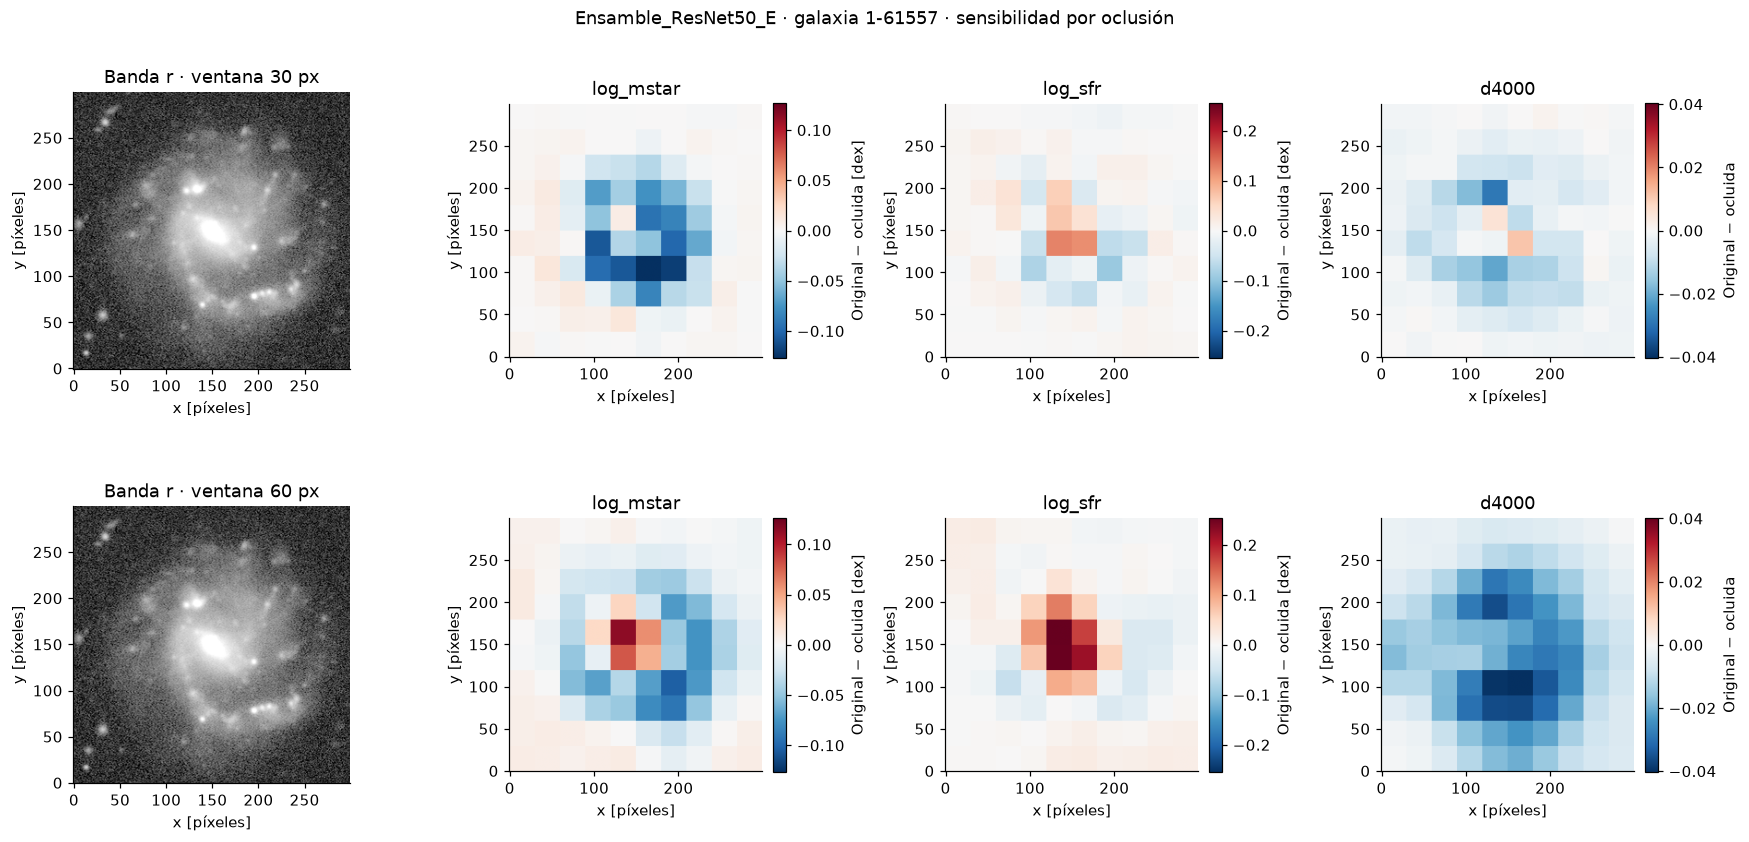

Para la galaxia 1-61557, los cambios absolutos máximos por ventana fueron log_mstar (30 px: 0.12674; 60 px: 0.15916), log_sfr (30 px: 0.12732; 60 px: 0.37336), d4000 (30 px: 0.02871; 60 px: 0.05236). Expresamos los cambios de masa y SFR en dex, y D4000 sin unidades. Los valores positivos del mapa indican que sustituir la región redujo la predicción; los negativos indican que la aumentó. Comparamos ambas ventanas con la misma escala de color por propiedad.

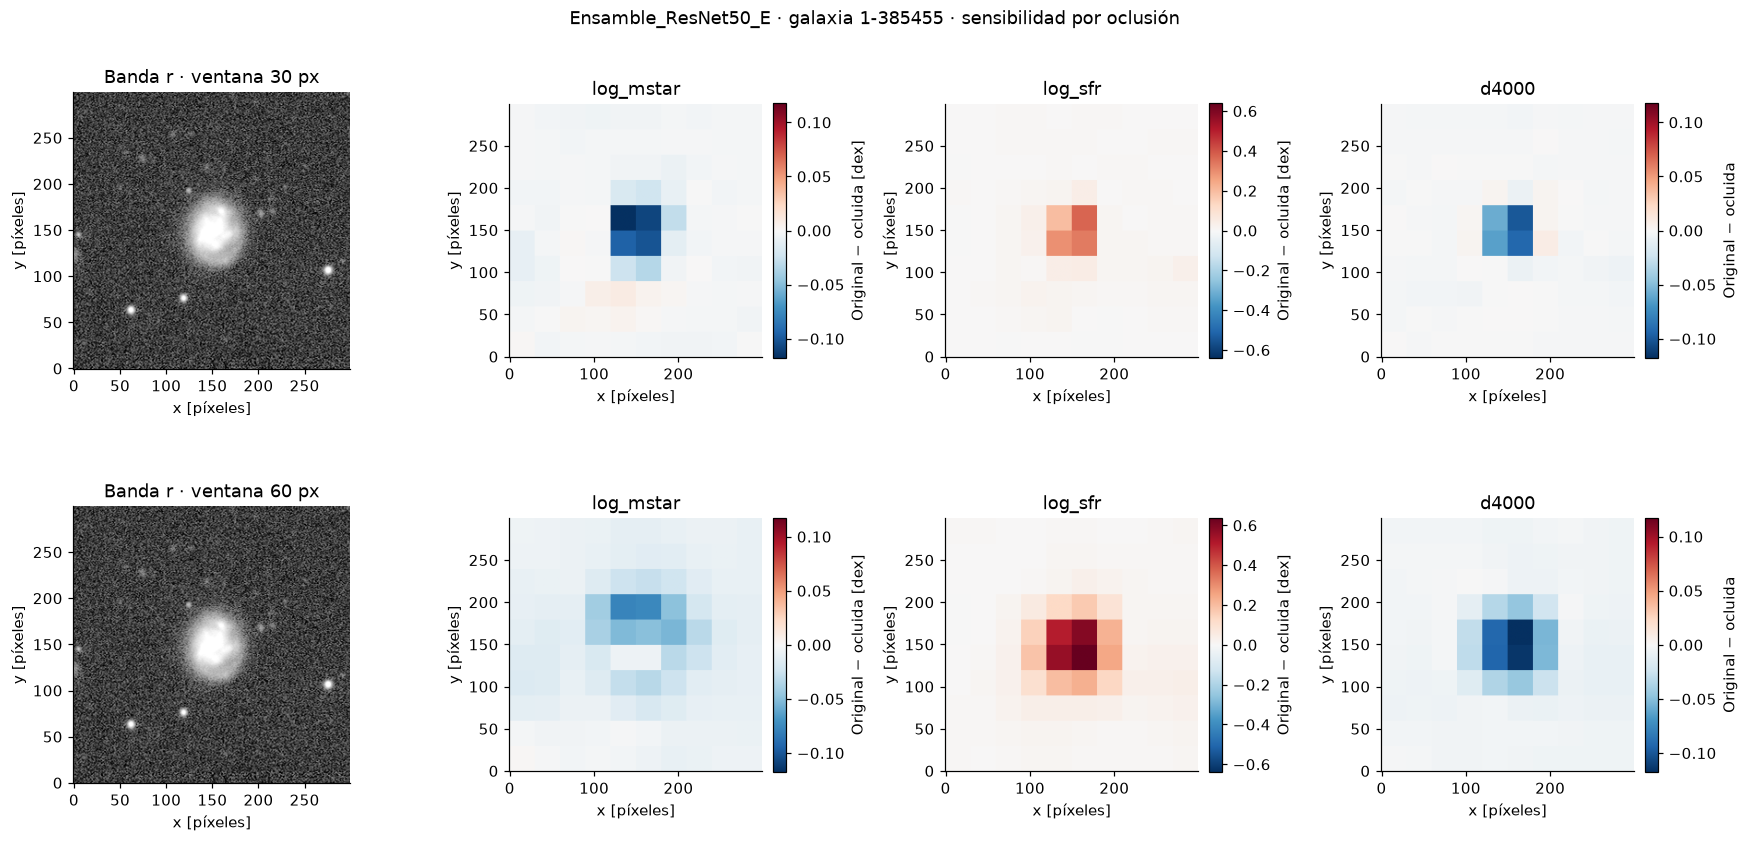

Para la galaxia 1-385455, los cambios absolutos máximos por ventana fueron log_mstar (30 px: 0.11772; 60 px: 0.13168), log_sfr (30 px: 0.36992; 60 px: 1.18919), d4000 (30 px: 0.10003; 60 px: 0.16696). Expresamos los cambios de masa y SFR en dex, y D4000 sin unidades. Los valores positivos del mapa indican que sustituir la región redujo la predicción; los negativos indican que la aumentó. Comparamos ambas ventanas con la misma escala de color por propiedad.

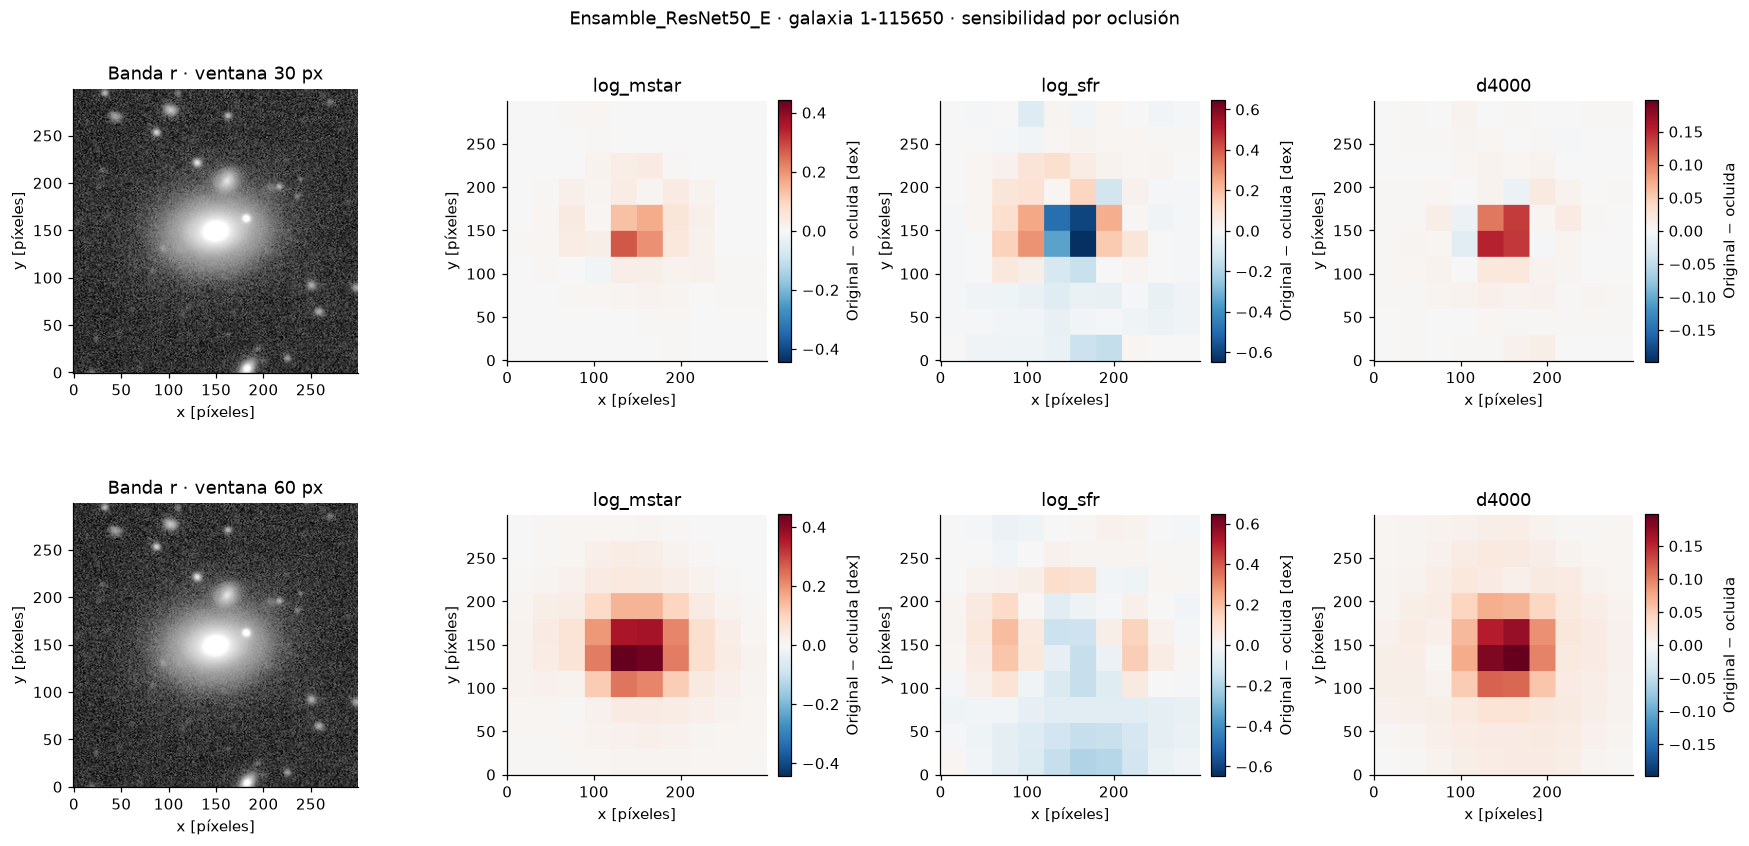

Para la galaxia 1-115650, los cambios absolutos máximos por ventana fueron log_mstar (30 px: 0.27365; 60 px: 0.50502), log_sfr (30 px: 0.64658; 60 px: 0.48512), d4000 (30 px: 0.15276; 60 px: 0.21974). Expresamos los cambios de masa y SFR en dex, y D4000 sin unidades. Los valores positivos del mapa indican que sustituir la región redujo la predicción; los negativos indican que la aumentó. Comparamos ambas ventanas con la misma escala de color por propiedad.

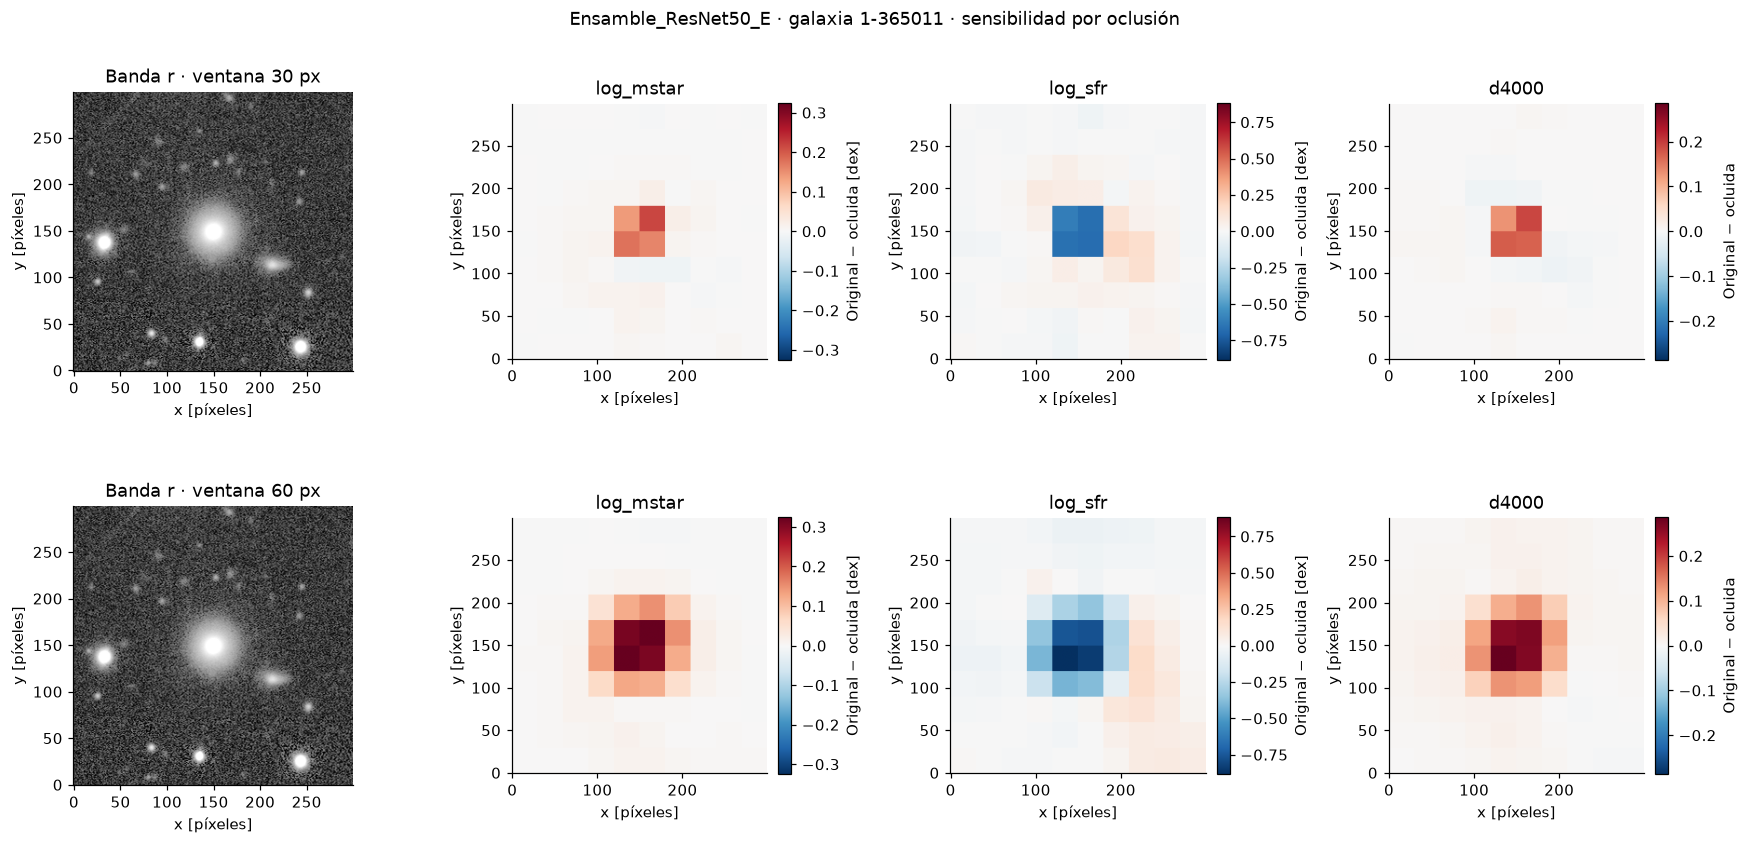

Para la galaxia 1-365011, los cambios absolutos máximos por ventana fueron log_mstar (30 px: 0.21788; 60 px: 0.48677), log_sfr (30 px: 0.67218; 60 px: 1.09993), d4000 (30 px: 0.19119; 60 px: 0.39112). Expresamos los cambios de masa y SFR en dex, y D4000 sin unidades. Los valores positivos del mapa indican que sustituir la región redujo la predicción; los negativos indican que la aumentó. Comparamos ambas ventanas con la misma escala de color por propiedad.

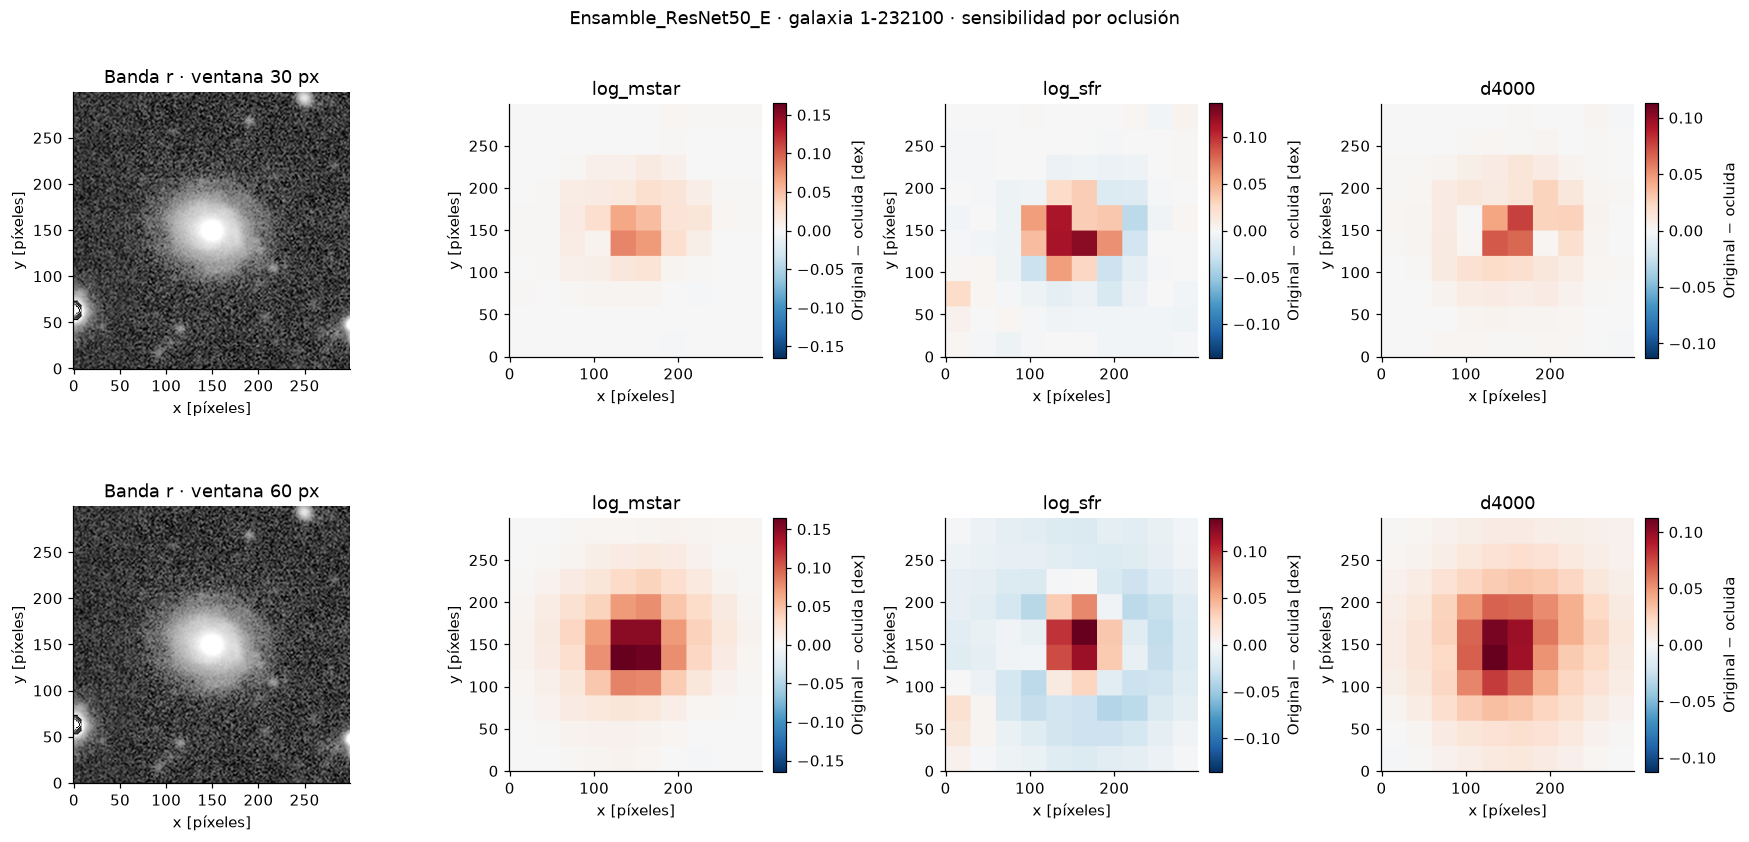

Para la galaxia 1-232100, los cambios absolutos máximos por ventana fueron log_mstar (30 px: 0.08116; 60 px: 0.25834), log_sfr (30 px: 0.12282; 60 px: 0.22831), d4000 (30 px: 0.07724; 60 px: 0.12662). Expresamos los cambios de masa y SFR en dex, y D4000 sin unidades. Los valores positivos del mapa indican que sustituir la región redujo la predicción; los negativos indican que la aumentó. Comparamos ambas ventanas con la misma escala de color por propiedad.

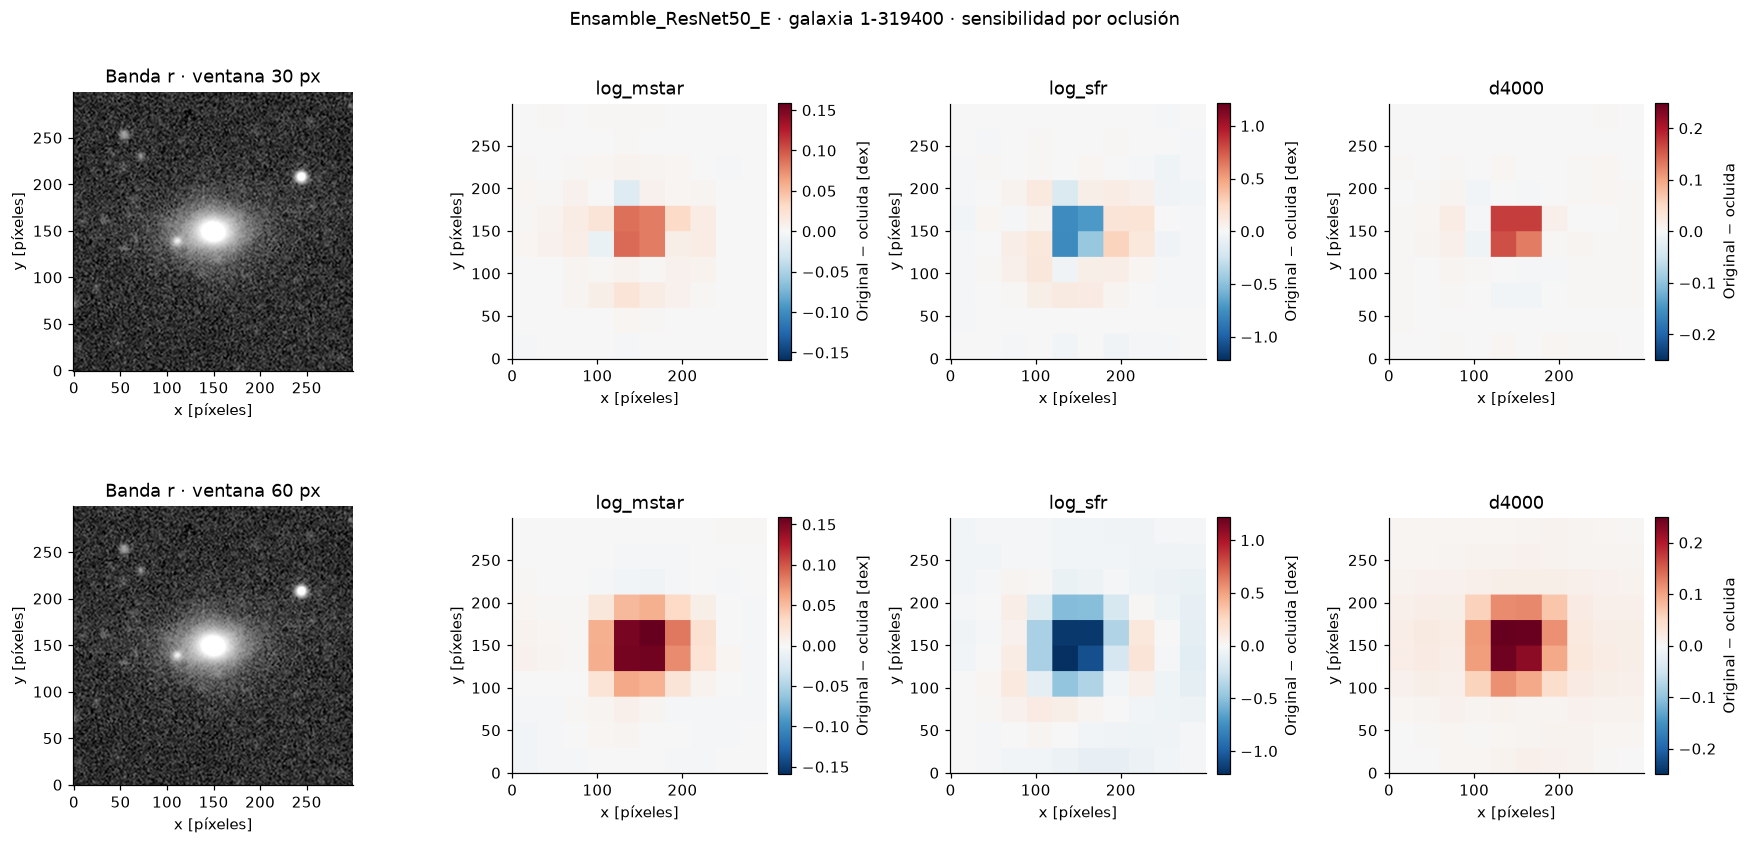

Para la galaxia 1-319400, los cambios absolutos máximos por ventana fueron log_mstar (30 px: 0.09025; 60 px: 0.24446), log_sfr (30 px: 0.77600; 60 px: 1.91523), d4000 (30 px: 0.17207; 60 px: 0.35132). Expresamos los cambios de masa y SFR en dex, y D4000 sin unidades. Los valores positivos del mapa indican que sustituir la región redujo la predicción; los negativos indican que la aumentó. Comparamos ambas ventanas con la misma escala de color por propiedad.

Análisis e interpretaciones guardados en: /home/a01796921/DESI_ensambles_homogeneos/2ea9b720bdfab52f/interpretabilidad/dcf40c7e2f5dd2b0


In [20]:
MAPAS_INTERP = {}; filas_parches = []; filas_mapas = []
for ix in IOCL:
    mangaid = str(VALIDACION.mangaid.iloc[ix]); base = BASE_INTERP[pos_union[int(ix)]]
    for ventana in CFG_INTERP['ventanas_px']:
        parches = interp_parches(300,300,ventana,CFG_INTERP['paso_px'])
        delta = base[None,:]-OCLUIDAS_INTERP[(int(ix),ventana)]
        mapa,cuentas = interp_mapa(parches,delta,300,300)
        MAPAS_INTERP[(int(ix),ventana)] = mapa
        np.savez_compressed(SALIDA_INTERP/f'occlusion_{mangaid}_{ventana}px.npz',
                            mapa=mapa,veces_cubierto=cuentas,objetivos=np.array(OBJETIVOS),
                            prediccion_original=base,ventana_px=ventana)
        for j,obj in enumerate(OBJETIVOS):
            k = int(np.argmax(np.abs(delta[:,j]))); y0,y1,x0,x1 = parches[k]
            filas_mapas.append({'mangaid':mangaid,'objetivo':obj,'ventana_px':ventana,
                'media_cambio_absoluto':float(np.mean(np.abs(delta[:,j]))),'max_cambio_absoluto':float(np.abs(delta[k,j])),
                'cambio_firmado_maximo':float(delta[k,j]),'centro_x_px':(x0+x1-1)/2,'centro_y_px':(y0+y1-1)/2})
        for k,(y0,y1,x0,x1) in enumerate(parches):
            for j,obj in enumerate(OBJETIVOS):
                filas_parches.append({'mangaid':mangaid,'ventana_px':ventana,'y0':y0,'y1':y1,'x0':x0,'x1':x1,
                    'objetivo':obj,'prediccion_original':base[j],
                    'prediccion_ocluida':OCLUIDAS_INTERP[(int(ix),ventana)][k,j],
                    'original_menos_ocluida':delta[k,j]})
RESUMEN_OCLUSION = pd.DataFrame(filas_mapas)
guardar_csv(RESUMEN_OCLUSION,SALIDA_INTERP/'resumen_occlusion.csv')
guardar_csv(pd.DataFrame(filas_parches),SALIDA_INTERP/'occlusion_por_region.csv')
display(RESUMEN_OCLUSION.round(6))
textos_occlusion = []
with PdfPages(SALIDA_INTERP/'mapas_occlusion.pdf') as pdf:
    for ix in IOCL:
        mangaid = str(VALIDACION.mangaid.iloc[ix])
        cubo = CUBOS_OCL[int(ix)]
        vista = np.arcsinh(cubo[1]/float(STATS_INTERP['asinh_escala'][1]))
        bajo,alto = np.quantile(vista,[.005,.995])
        nv = len(CFG_INTERP['ventanas_px'])
        fig,ejes = plt.subplots(nv,4,figsize=(16,4*nv),squeeze=False)
        limites = [max(float(np.max(np.abs(MAPAS_INTERP[(int(ix),v)][j]))) for v in CFG_INTERP['ventanas_px'])
                   for j in range(3)]
        for fila,ventana in enumerate(CFG_INTERP['ventanas_px']):
            ejes[fila,0].imshow(vista,origin='lower',cmap='gray',vmin=bajo,vmax=alto)
            ejes[fila,0].set(title=f'Banda r · ventana {ventana} px',xlabel='x [píxeles]',ylabel='y [píxeles]')
            for j,obj in enumerate(OBJETIVOS):
                eje=ejes[fila,j+1]; limite=max(limites[j],1e-10)
                im=eje.imshow(MAPAS_INTERP[(int(ix),ventana)][j],origin='lower',cmap='RdBu_r',vmin=-limite,vmax=limite)
                eje.set(title=obj,xlabel='x [píxeles]',ylabel='y [píxeles]')
                barra=fig.colorbar(im,ax=eje,fraction=.046,pad=.04)
                barra.set_label('Original − ocluida'+(' [dex]' if obj!='d4000' else ''))
        fig.suptitle(f'{GANADOR_LOCAL} · galaxia {mangaid} · sensibilidad por oclusión')
        fig.tight_layout();fig.savefig(SALIDA_INTERP/f'mapas_occlusion_{mangaid}.png',bbox_inches='tight')
        pdf.savefig(fig,bbox_inches='tight');plt.show();plt.close(fig)
        fragmentos=[]
        for obj in OBJETIVOS:
            t=RESUMEN_OCLUSION.loc[(RESUMEN_OCLUSION.mangaid==mangaid)&(RESUMEN_OCLUSION.objetivo==obj)]
            partes=[f'{int(f.ventana_px)} px: {f.max_cambio_absoluto:.5f}' for f in t.itertuples()]
            fragmentos.append(obj+' ('+'; '.join(partes)+')')
        texto=(f'Para la galaxia {mangaid}, los cambios absolutos máximos por ventana fueron '+', '.join(fragmentos)+
               '. Expresamos los cambios de masa y SFR en dex, y D4000 sin unidades. Los valores positivos del mapa '
               'indican que sustituir la región redujo la predicción; los negativos indican que la aumentó. '
               'Comparamos ambas ventanas con la misma escala de color por propiedad.')
        textos_occlusion.append(texto);display(Markdown(texto))
TEXTO_OCLUSION = ('Exploramos seis ejemplos distribuidos por masa' if len(IOCL)==6 else f'Exploramos {len(IOCL)} ejemplos distribuidos por masa')
TEXTO_OCLUSION += ('. La referencia es la mediana recortada de la franja exterior de cada banda, transformada con '
    'los estadísticos de Train. Puede contener emisión de la propia galaxia o fuentes vecinas; por ello los mapas '
    'describen sensibilidad a esa sustitución, no una segmentación física ni una identificación automática del bulbo o del disco. '
    'Los mapas promedian el cambio de las ventanas que cubren cada píxel.\n\n'+'\n\n'.join(textos_occlusion))
INTERPRETACIONES.append({'grafico':'mapas_occlusion','interpretacion':TEXTO_OCLUSION})
guardar_json({'permutacion':TEXTO_PERMUTACION,'occlusion':TEXTO_OCLUSION},SALIDA_INTERP/'interpretaciones.json')
(SALIDA_INTERP/'interpretacion.md').write_text('## Importancia de las entradas\n\n'+TEXTO_PERMUTACION+
    '\n\n## Sensibilidad por oclusión\n\n'+TEXTO_OCLUSION,encoding='utf-8')
guardar_json(INTERPRETACIONES,SALIDA/'interpretaciones_graficos.json')
print('Análisis e interpretaciones guardados en:',SALIDA_INTERP)


## 13. Selección y archivos para la entrega

Guardamos los resultados por propiedad, el ranking, los tiempos, las configuraciones probadas, las predicciones externas del combinador y los pesos finales. También exportamos las figuras en PNG, reunimos los cuatro gráficos de rendimiento en PDF y añadimos las tablas de importancia, los mapas de oclusión y sus interpretaciones. El ZIP agrupa los resultados de esta etapa para compartirlos con el equipo.

El archivo `ensamble_final.json` de cada familia conserva los pesos en el orden de semillas 42, 7 y 2026 y de objetivos `log_mstar`, `log_sfr` y `d4000`. Para aplicar el ensamble a nuevas galaxias necesitaremos las predicciones de esos mismos checkpoints con su preprocesamiento original. Los pesos guardados por sí solos no sustituyen las redes base.

Priorizamos la precisión conjunta sin perder de vista los errores de cada propiedad y el costo de ejecutar tres redes. La última celda redacta la conclusión con los resultados calculados y diferencia el mejor ensamble del ganador de la comparación local.

In [21]:
fila_ganador = RANKING.set_index('modelo').loc[GANADOR_LOCAL]
fila_ensamble = RANKING.set_index('modelo').loc[MEJOR_ENSAMBLE]
valor_base = float(RANKING.set_index('modelo').loc[BASE_INDIVIDUAL,'MSE_normalizado_global'])
valor_mejor = float(fila_ensamble.MSE_normalizado_global)
mejora = 100 * (valor_base - valor_mejor) / valor_base if valor_base > 0 else 0.0
parrafos = [f'## Modelo con mejores resultados\n\n'
            f'Entre los dos ensambles homogéneos, obtuvimos el menor MSE normalizado global con {MEJOR_ENSAMBLE}: '
            f'{valor_mejor:.6f}. En la comparación con ResNet50_E_s42, el primer lugar correspondió a {GANADOR_LOCAL}, '
            f'con {fila_ganador.MSE_normalizado_global:.6f}, sobre las {len(Y):,} galaxias de Validation.']
if valor_mejor < valor_base - 1e-12:
    parrafos.append(f'El mejor ensamble redujo el criterio global un {mejora:.2f} % respecto al modelo individual '
                    f'({valor_base:.6f}). Lo seleccionamos como candidato de esta etapa.')
elif abs(valor_mejor-valor_base) <= 1e-12:
    parrafos.append('El mejor ensamble empató numéricamente con el modelo individual. Conservamos el individual '
                    'como candidato local porque requiere una sola red para predecir.')
else:
    parrafos.append(f'El mejor ensamble aumentó el criterio un {-mejora:.2f} % respecto al individual '
                    f'({valor_base:.6f}). Por ello conservamos ResNet50_E_s42 como candidato local.')
for letra,r in RESULTADOS.items():
    c=r['configuracion_final']
    texto=(f'Para el ensamble {letra} elegimos el promedio uniforme.' if c['alcance']=='uniforme' else
           f'Para el ensamble {letra} elegimos pesos de alcance {c["alcance"].replace("_"," ")} y λ = {c["lambda"]:g}.')
    parrafos.append(texto+' La elección provino de las configuraciones ejecutadas y registradas en la búsqueda interna.')
met = METRICAS.loc[METRICAS.modelo.eq(GANADOR_LOCAL)].set_index('objetivo')
parrafos.append('Con el candidato local obtuvimos '+ '; '.join(
    f'{o}: MAE {met.loc[o,"MAE"]:.6f}, RMSE {met.loc[o,"RMSE"]:.6f}, sesgo {met.loc[o,"sesgo"]:+.6f} '
    f'y R² {met.loc[o,"R2"]:.6f}' for o in OBJETIVOS)+'. Expresamos los errores de masa y SFR en dex, y los de D4000 sin unidades.')
parrafos.append(f'El candidato seleccionado utiliza {int(fila_ganador.redes)} '
                f'{"red" if fila_ganador.redes == 1 else "redes"} para predecir. '
                +(f'Recuperamos {fila_ganador.minutos_redes_base:.2f} minutos acumulados de entrenamiento de sus redes base '
                  if pd.notna(fila_ganador.minutos_redes_base) else
                  'No contamos con todos los historiales para reconstruir el tiempo de sus redes base ')
                +f'y medimos {fila_ganador.segundos_busqueda_combinador + fila_ganador.segundos_ajuste_final:.3f} segundos '
                'en la búsqueda y el ajuste del combinador en esta ejecución. Priorizamos el menor error global '
                'para la estimación de propiedades galácticas y dejamos explícito el costo adicional de usar varias redes.')
parrafos.append('Para evaluar los ensambles usamos predicciones fuera de los pliegues de ajuste del combinador. '
                'Las redes base ya habían utilizado Validation para seleccionar sus checkpoints, por lo que '
                'interpretamos esta comparación como una etapa de desarrollo. Integraremos estos resultados '
                'con los ensambles heterogéneos del equipo antes de cerrar la selección general. No evaluamos Test en este notebook.')
CONCLUSION = '\n\n'.join(parrafos)
SELECCION = {'ganador_local': GANADOR_LOCAL, 'mejor_ensamble': MEJOR_ENSAMBLE,
             'MSE_normalizado_global': float(fila_ganador.MSE_normalizado_global),
             'n_validation': len(Y), 'test_evaluado_en_este_notebook': False,
             'seleccion_general_equipo_pendiente': True, 'identidad': IDENTIDAD,
             'fecha_utc': datetime.now(timezone.utc).isoformat()}
guardar_json(SELECCION,SALIDA/'seleccion_homogeneos.json')
(SALIDA/'conclusion.md').write_text(CONCLUSION,encoding='utf-8')
informe = CONCLUSION+'\n\n'+'\n\n'.join('### '+d['grafico']+'\n\n'+d['interpretacion'] for d in INTERPRETACIONES)
(SALIDA/'informe_resultados.md').write_text(informe,encoding='utf-8')


8155

In [22]:
archivo_zip=SALIDA/'resultados_ensambles_homogeneos.zip'
with zipfile.ZipFile(archivo_zip,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in sorted(SALIDA.rglob('*')):
        relativa=p.relative_to(SALIDA)
        if 'cache' in relativa.parts:
            continue
        if 'interpretabilidad' in relativa.parts and SALIDA_INTERP not in p.parents:
            continue
        if p.is_file() and p.suffix in ['.csv','.json','.md','.png','.pdf','.npz']:
            z.write(p,relativa)
print('Guardamos las métricas, los pesos, las búsquedas, la importancia de las entradas, los mapas y la conclusión en:')
print(SALIDA)
display(FileLink(str(archivo_zip)))


Guardamos las métricas, los pesos, las búsquedas, la importancia de las entradas, los mapas y la conclusión en:
/home/a01796921/DESI_ensambles_homogeneos/2ea9b720bdfab52f


/home/a01796921/DESI_ensambles_homogeneos/2ea9b720bdfab52f/resultados_ensambles_homogeneos.zip

## Declaración de IA

Utilizamos ChatGPT GPT-6 como apoyo para desarrollar el código marco, organizar las etapas del notebook y revisar las alternativas de combinación de las redes. Mediante intercambios de revisión y mejora trabajamos en la búsqueda de hiperparámetros, la separación entre ajuste y evaluación del combinador, la presentación de las métricas y la incorporación de la importancia por permutación y la sensibilidad por oclusión. Conservamos en el equipo la responsabilidad de ejecutar el código, verificar sus resultados e interpretar los hallazgos dentro del problema astronómico.

Partimos de las decisiones técnicas y astronómicas documentadas en los modelos originales, incluida la incorporación del redshift sugerida por el Dr. Iván Reyes Amezcua. En esta etapa combinamos las predicciones en sus unidades originales y mantenemos las transformaciones de las redes previamente entrenadas. Las configuraciones y conclusiones que reportamos se obtienen de la ejecución registrada del notebook.

## Referencias metodológicas

Consultamos la documentación de scikit-learn sobre [promedio de predicciones para regresión](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingRegressor.html) y [validación cruzada anidada](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html). Adaptamos estos principios a las predicciones guardadas de nuestras redes; no utilizamos la clase VotingRegressor para volver a entrenarlas.

Para la interpretación consultamos la documentación sobre [importancia por permutación](https://scikit-learn.org/stable/modules/permutation_importance.html) y [oclusión de entradas](https://captum.ai/api/occlusion.html). Implementamos la oclusión por lotes con NumPy y PyTorch, sin requerir Captum como dependencia.

La siguiente celda muestra la conclusión de esta ejecución.

In [23]:
display(Markdown(CONCLUSION))


## Modelo con mejores resultados

Entre los dos ensambles homogéneos, obtuvimos el menor MSE normalizado global con Ensamble_ResNet50_E: 0.118602. En la comparación con ResNet50_E_s42, el primer lugar correspondió a Ensamble_ResNet50_E, con 0.118602, sobre las 1,261 galaxias de Validation.

El mejor ensamble redujo el criterio global un 7.25 % respecto al modelo individual (0.127879). Lo seleccionamos como candidato de esta etapa.

Para el ensamble D elegimos pesos de alcance por objetivo y λ = 0.01. La elección provino de las configuraciones ejecutadas y registradas en la búsqueda interna.

Para el ensamble E elegimos el promedio uniforme. La elección provino de las configuraciones ejecutadas y registradas en la búsqueda interna.

Con el candidato local obtuvimos log_mstar: MAE 0.078610, RMSE 0.103993, sesgo +0.002904 y R² 0.974848; log_sfr: MAE 0.380843, RMSE 0.573167, sesgo -0.014561 y R² 0.757310; d4000: MAE 0.051014, RMSE 0.071312, sesgo +0.007745 y R² 0.908433. Expresamos los errores de masa y SFR en dex, y los de D4000 sin unidades.

El candidato seleccionado utiliza 3 redes para predecir. Recuperamos 107.04 minutos acumulados de entrenamiento de sus redes base y medimos 0.640 segundos en la búsqueda y el ajuste del combinador en esta ejecución. Priorizamos el menor error global para la estimación de propiedades galácticas y dejamos explícito el costo adicional de usar varias redes.

Para evaluar los ensambles usamos predicciones fuera de los pliegues de ajuste del combinador. Las redes base ya habían utilizado Validation para seleccionar sus checkpoints, por lo que interpretamos esta comparación como una etapa de desarrollo. Integraremos estos resultados con los ensambles heterogéneos del equipo antes de cerrar la selección general. No evaluamos Test en este notebook.